# NLP clásico aplicado a IMDB: Bag of Words y TF-IDF

**Dataset:** `movie_review_kaggle.csv.gz`  
**Problema:** clasificación de sentimiento en reseñas de películas.  
**Modelo de clasificación:** Logistic Regression.  
**Representaciones estudiadas:** **Bag of Words (BoW)** y **TF-IDF**.

Este notebook conserva el dataset y el flujo general de la versión original, pero concentra la clase en dos representaciones fundamentales del lenguaje: contar palabras y ponderar su importancia.

---

## Objetivos de aprendizaje

Al finalizar el notebook, el estudiante estará en capacidad de:

1. Realizar una exploración básica de un corpus textual.
2. Identificar ruido, documentos duplicados, longitudes extremas y palabras frecuentes.
3. Aplicar una limpieza de texto apropiada para análisis de sentimiento.
4. Explicar matemáticamente cómo se construye una matriz documento–término.
5. Representar documentos con Bag of Words.
6. Explicar y calcular la intuición de TF, DF, IDF y TF-IDF.
7. Entrenar y evaluar clasificadores usando ambas representaciones.
8. Interpretar las palabras más influyentes y analizar errores del modelo.

---

## Ruta sugerida para una clase de 60 minutos

| Bloque | Tiempo |
|---|---:|
| Contexto, carga y EDA | 10 min |
| Limpieza del texto | 10 min |
| Bag of Words | 15 min |
| TF-IDF | 15 min |
| Comparación, interpretación y cierre | 10 min |

# 0. Configuración inicial

Un pipeline reproducible debe dejar explícitos:

- El archivo utilizado.
- Las columnas de texto y etiqueta.
- Las reglas de limpieza.
- La división de entrenamiento y prueba.
- La semilla aleatoria.
- Las métricas de evaluación.

El dataset se mantiene igual al de la versión entregada: `movie_review_kaggle.csv.gz`.

In [1]:
# ============================================================
# 0.1 Imports generales
# ============================================================

import os
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
pd.set_option("display.max_colwidth", 180)

In [2]:
# ============================================================
# 0.2 Cargar el mismo dataset de la versión original
# ============================================================

DATA_PATH = "movie_review_kaggle.csv.gz"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"No se encontró '{DATA_PATH}'. "
        "Coloque el archivo en la misma carpeta del notebook."
    )

df_raw = pd.read_csv(DATA_PATH)
print("Dimensión original:", df_raw.shape)
df_raw.head(10)

Dimensión original: (10000, 2)


,review,sentiment
0,"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of ...",positive
1,Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many diffe...,positive
2,The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by S...,negative
3,"Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attitude of Emma. She is funny without being excessively silly, y...",positive
4,"Expectations were somewhat high for me when I went to see this movie, after all I thought Steve Carell could do no wrong coming off of great movies like Anchorman, The 40 Year-...",negative
5,"I've watched this movie on a fairly regular basis for most of my life, and it never gets old. For all the snide remarks and insults (mostly from David Spade), ""Tommy Boy"" has a...",positive
6,"For once a story of hope highlighted over the tragic reality our youth face. Favela Rising draws one into a scary, unsafe and unfair world and shows through beautiful color and...",positive
7,"Okay, I didn't get the Purgatory thing the first time I watched this episode. It seemed like something significant was going on that I couldn't put my finger on. This time thos...",positive
8,"I was very disappointed with this series. It had lots of cool graphics and that's about it. The level of detail it went into was minimal, and I always got the feeling the audie...",negative
9,"The first 30 minutes of Tinseltown had my finger teetering on the remote, poised to flick around to watch something else. The premise of two writers, down on their luck, living...",negative


## 0.3 Definición y validación de columnas

El dataset debe contener:

- `review`: texto de la reseña.
- `sentiment`: etiqueta, normalmente `positive` o `negative`.

Se crea además una variable numérica `target`:

$$
\text{negative}=0, \qquad \text{positive}=1
$$

Conservaremos una copia del dataset original en `df_raw` y utilizaremos `df` para el análisis.


In [3]:
TEXT_COL = "review"
LABEL_COL = "sentiment"
TARGET_COL = "target"

required_columns = {TEXT_COL, LABEL_COL}
missing_columns = required_columns - set(df_raw.columns)

if missing_columns:
    raise ValueError(f"Faltan columnas requeridas: {missing_columns}")

df = df_raw.copy()

# Normalización robusta de etiquetas
df["sentiment_label"] = df[LABEL_COL].astype(str).str.strip().str.lower()

label_map = {
    "negative": 0,
    "positive": 1,
    "0": 0,
    "1": 1
}
df[TARGET_COL] = df["sentiment_label"].map(label_map)

if df[TARGET_COL].isna().any():
    unknown = df.loc[df[TARGET_COL].isna(), LABEL_COL].drop_duplicates().tolist()
    raise ValueError(f"Se encontraron etiquetas no reconocidas: {unknown}")

df[TARGET_COL] = df[TARGET_COL].astype(int)

df[[TEXT_COL, LABEL_COL, "sentiment_label", TARGET_COL]].head()

,review,sentiment,sentiment_label,target
0,"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of ...",positive,positive,1
1,Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many diffe...,positive,positive,1
2,The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by S...,negative,negative,0
3,"Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attitude of Emma. She is funny without being excessively silly, y...",positive,positive,1
4,"Expectations were somewhat high for me when I went to see this movie, after all I thought Steve Carell could do no wrong coming off of great movies like Anchorman, The 40 Year-...",negative,negative,0


# 1. Exploración de datos textuales

En datos tabulares solemos revisar distribuciones numéricas. En NLP también necesitamos estudiar:

- Cantidad de documentos.
- Balance de clases.
- Valores faltantes y duplicados.
- Longitud de las reseñas.
- Presencia de HTML, URLs u otros patrones.
- Frecuencias de palabras.
- Tamaño y dispersión potencial del vocabulario.

Estas decisiones influyen directamente en BoW y TF-IDF porque ambas técnicas construyen una columna por término del vocabulario.

In [4]:
# ============================================================
# 1.1 Calidad básica de datos
# ============================================================

quality_summary = pd.DataFrame({
    "métrica": [
        "filas",
        "columnas",
        "reviews nulas",
        "etiquetas nulas",
        "reviews duplicadas",
        "pares review-etiqueta duplicados"
    ],
    "valor": [
        len(df),
        df.shape[1],
        df[TEXT_COL].isna().sum(),
        df[LABEL_COL].isna().sum(),
        df.duplicated(subset=[TEXT_COL]).sum(),
        df.duplicated(subset=[TEXT_COL, LABEL_COL]).sum()
    ]
})

display(quality_summary)

,métrica,valor
0,filas,10000
1,columnas,4
2,reviews nulas,0
3,etiquetas nulas,0
4,reviews duplicadas,22
5,pares review-etiqueta duplicados,22


### Decisión sobre nulos y duplicados

Los documentos nulos no pueden vectorizarse. Además, reseñas duplicadas pueden aparecer tanto en entrenamiento como en prueba y producir una evaluación demasiado optimista.

Por ello:

1. Eliminamos filas sin texto o etiqueta.
2. Eliminamos duplicados exactos de `review` y `sentiment`.
3. Conservamos el mismo dataset de origen; únicamente creamos una versión válida para modelado.

In [5]:
rows_before = len(df)

df = (
    df.dropna(subset=[TEXT_COL, LABEL_COL])
      .drop_duplicates(subset=[TEXT_COL, LABEL_COL])
      .reset_index(drop=True)
)

rows_after = len(df)

print("Filas antes:", rows_before)
print("Filas después:", rows_after)
print("Filas removidas:", rows_before - rows_after)

Filas antes: 10000
Filas después: 9978
Filas removidas: 22


,sentiment,reviews,proporción
0,positive,5035,0.50461
1,negative,4943,0.49539


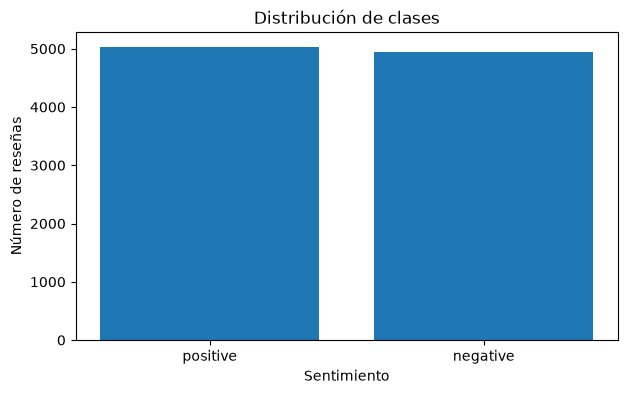

In [6]:
# ============================================================
# 1.2 Balance de clases
# ============================================================

class_counts = (
    df["sentiment_label"]
    .value_counts()
    .rename_axis("sentiment")
    .reset_index(name="reviews")
)

class_counts["proporción"] = class_counts["reviews"] / class_counts["reviews"].sum()
display(class_counts)

plt.figure(figsize=(7, 4))
plt.bar(class_counts["sentiment"], class_counts["reviews"])
plt.title("Distribución de clases")
plt.xlabel("Sentimiento")
plt.ylabel("Número de reseñas")
plt.show()

## Ejercicio 1

1. ¿Cuántas reseñas válidas quedan?
2. ¿El problema está aproximadamente balanceado?
3. ¿Por qué un conjunto muy desbalanceado puede hacer que `accuracy` sea engañosa?

In [7]:
# Solución Ejercicio 1
print("Reseñas válidas (sin nulos ni duplicados):", len(df))
display(class_counts.round(4))
ratio = class_counts["reviews"].min() / class_counts["reviews"].max()
print("Razón clase minoritaria / mayoritaria:", round(ratio, 4))

# Accuracy de un clasificador trivial que siempre predice la clase mayoritaria
print("Accuracy del clasificador trivial (clase mayoritaria):",
      round(class_counts["proporción"].max(), 4))


Reseñas válidas (sin nulos ni duplicados): 9978


,sentiment,reviews,proporción
0,positive,5035,0.5046
1,negative,4943,0.4954


Razón clase minoritaria / mayoritaria: 0.9817
Accuracy del clasificador trivial (clase mayoritaria): 0.5046


### Respuesta Ejercicio 1

1. **Reseñas válidas:** después de eliminar nulos y pares reseña-etiqueta duplicados quedan **9 978 reseñas**.
2. **Balance:** sí, está prácticamente balanceado: **5 035 positivas (50,46 %)** y **4 943 negativas (49,54 %)**; la razón minoritaria/mayoritaria es 0,98.
3. **Accuracy engañosa con desbalance:** si, por ejemplo, el 95 % de las reseñas fueran positivas, un modelo trivial que *siempre* predice "positive" tendría 95 % de accuracy sin haber aprendido nada y fallaría en todos los negativos. Accuracy promedia sobre todas las observaciones, así que la clase mayoritaria domina la métrica. Por eso conviene mirar precision, recall, F1 (por clase) y ROC-AUC. Aquí la referencia trivial es solo 50,46 %, de modo que la accuracy sí es informativa.


In [8]:
# ============================================================
# 1.3 Longitud de los documentos
# ============================================================

df["num_chars"] = df[TEXT_COL].astype(str).apply(len)
df["num_words"] = df[TEXT_COL].astype(str).apply(lambda text: len(text.split()))

display(df[[TEXT_COL, "sentiment_label", "num_chars", "num_words"]].head())

print("Estadísticas generales:")
display(df[["num_chars", "num_words"]].describe().round(2))

print("Promedios por clase:")
display(
    df.groupby("sentiment_label")[["num_chars", "num_words"]]
      .mean()
      .round(2)
)

,review,sentiment_label,num_chars,num_words
0,"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of ...",positive,1107,201
1,Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many diffe...,positive,2054,354
2,The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by S...,negative,653,119
3,"Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attitude of Emma. She is funny without being excessively silly, y...",positive,632,99
4,"Expectations were somewhat high for me when I went to see this movie, after all I thought Steve Carell could do no wrong coming off of great movies like Anchorman, The 40 Year-...",negative,1900,332


Estadísticas generales:


,num_chars,num_words
count,9978.00,9978.00
mean,1314.16,231.88
std,984.05,170.41
min,41.00,9.00
25%,700.00,126.00
50%,975.00,173.00
75%,1596.00,282.00
max,7164.00,1316.00


Promedios por clase:


,num_chars,num_words
sentiment_label,,
negative,1305.51,231.31
positive,1322.66,232.43


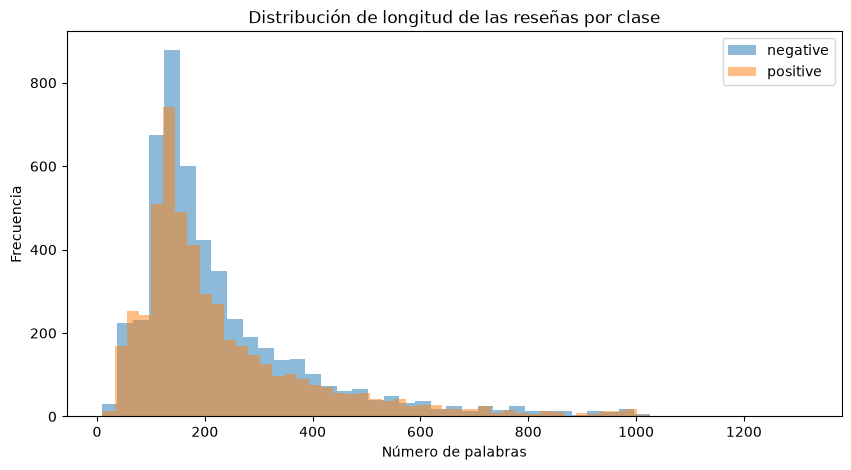

In [9]:
plt.figure(figsize=(10, 5))

for label in sorted(df["sentiment_label"].unique()):
    subset = df.loc[df["sentiment_label"] == label, "num_words"]
    plt.hist(subset, bins=45, alpha=0.5, label=label)

plt.title("Distribución de longitud de las reseñas por clase")
plt.xlabel("Número de palabras")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

In [10]:
# Reseñas particularmente cortas o largas
display(
    df.nsmallest(5, "num_words")[
        [TEXT_COL, "sentiment_label", "num_words"]
    ]
)

display(
    df.nlargest(5, "num_words")[
        [TEXT_COL, "sentiment_label", "num_words"]
    ]
)

,review,sentiment_label,num_words
5719,"What a script, what a story, what a mess!",negative,9
6495,Brilliant and moving performances by Tom Courtenay and Peter Finch.,positive,10
5987,Adrian Pasdar is excellent is this film. He makes a fascinating woman.,positive,12
8415,This is a great movie. Too bad it is not available on home video.,positive,14
4894,Absolutely fantastic! Whatever I say wouldn't do this underrated movie the justice it deserves. Watch it now! FANTASTIC!,positive,18


,review,sentiment_label,num_words
8356,"Okay, so I'm not a big video game buff, but was the game House of the Dead really famous enough to make a movie from? Sure, they went as far as to actually put in quick video g...",negative,1316
3801,"If you've seen the trailer for this movie, you pretty much know what to expect, because what you see here is what you get. And even if you haven't seen the previews, it won't t...",positive,1024
585,"Warning: Spoilers Galore!<br /><br />Tim Burton remaking this sui generis movie is about as sensible as remaking Psycho - oh, that's right, some idiot already did that - I rest...",negative,1010
6187,"The vigilante has long held a fascination for audiences, inasmuch as it evokes a sense of swift, sure justice; good triumphs over evil and the bad guy gets his deserts. It is, ...",positive,1007
9626,"How strange the human mind is; this center of activity wherein perceptions of reality are formed and stored, and in which one's view of the world hinges on the finely tuned fun...",positive,1006


## 1.4 Ruido visible en el texto

Las reseñas de IMDB pueden contener marcas HTML como `<br />`. También pueden aparecer URLs, números o puntuación repetida.

Antes de limpiar, conviene medir el problema en lugar de asumir que existe.

In [11]:
def contains_html(text):
    return bool(re.search(r"<[^>]+>", str(text)))

def contains_url(text):
    return bool(re.search(r"https?://\S+|www\.\S+", str(text)))

df["has_html"] = df[TEXT_COL].apply(contains_html)
df["has_url"] = df[TEXT_COL].apply(contains_url)

noise_summary = pd.DataFrame({
    "patrón": ["HTML", "URL"],
    "documentos": [df["has_html"].sum(), df["has_url"].sum()],
    "porcentaje": [
        100 * df["has_html"].mean(),
        100 * df["has_url"].mean()
    ]
})

display(noise_summary.round(2))

,patrón,documentos,porcentaje
0,HTML,5868,58.81
1,URL,32,0.32


## 1.5 Frecuencias de palabras

Las frecuencias ofrecen una primera aproximación al contenido del corpus. Sin embargo:

- Las palabras funcionales suelen dominar los conteos.
- Una palabra frecuente no es necesariamente discriminativa.
- Una palabra rara puede ser ruido o una señal específica.
- Estas observaciones motivan posteriormente el uso de TF-IDF.

In [12]:
def simple_tokenize(text):
    """Tokenización sencilla para EDA; no reemplaza un tokenizer lingüístico."""
    return re.findall(r"\b[a-zA-Z]+\b", str(text).lower())


def get_top_words(texts, n=20, remove_stopwords=False):
    all_words = []

    for text in texts:
        tokens = simple_tokenize(text)

        if remove_stopwords:
            tokens = [
                word for word in tokens
                if word not in ENGLISH_STOP_WORDS
            ]

        all_words.extend(tokens)

    return Counter(all_words).most_common(n)


def plot_top_words(top_words, title):
    words = [word for word, _ in top_words]
    counts = [count for _, count in top_words]

    plt.figure(figsize=(11, 5))
    plt.bar(words, counts)
    plt.title(title)
    plt.xlabel("Palabra")
    plt.ylabel("Frecuencia")
    plt.xticks(rotation=45, ha="right")
    plt.show()

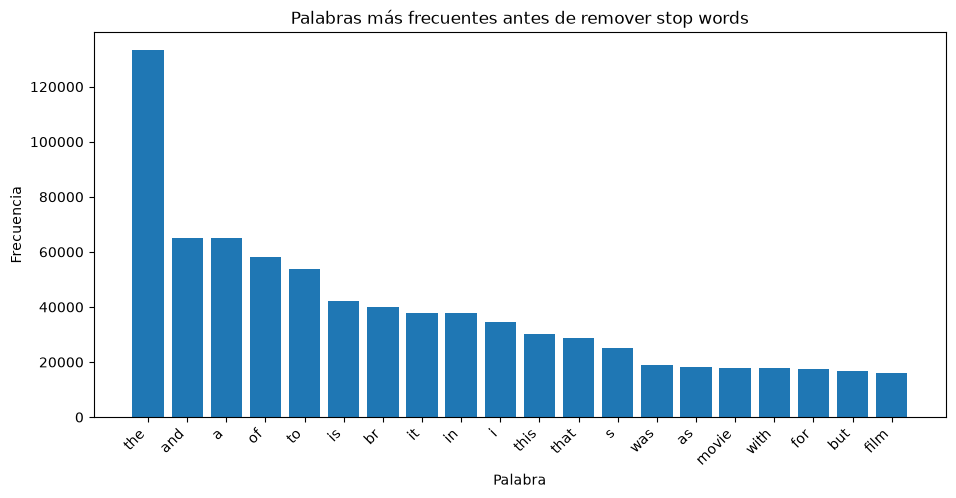

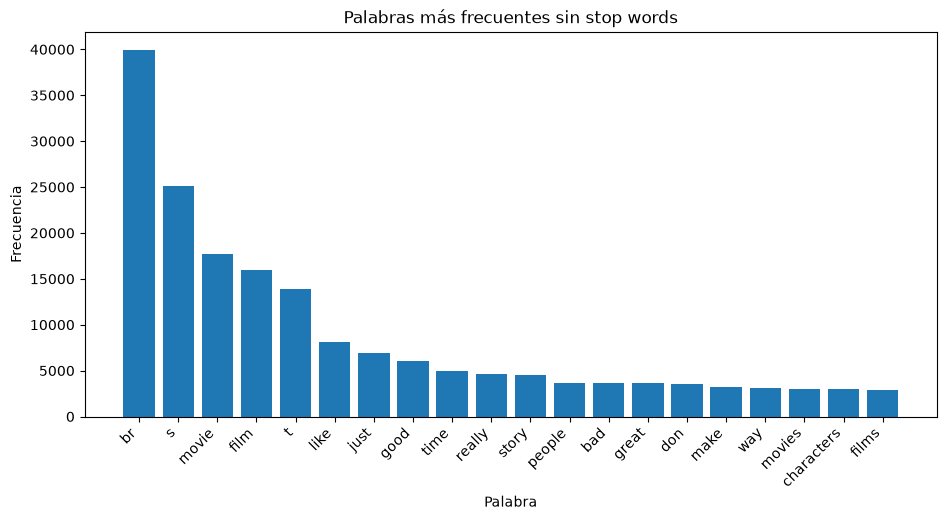

In [13]:
top_raw = get_top_words(df[TEXT_COL], n=20, remove_stopwords=False)
top_without_stopwords = get_top_words(
    df[TEXT_COL], n=20, remove_stopwords=True
)

plot_top_words(
    top_raw,
    "Palabras más frecuentes antes de remover stop words"
)

plot_top_words(
    top_without_stopwords,
    "Palabras más frecuentes sin stop words"
)

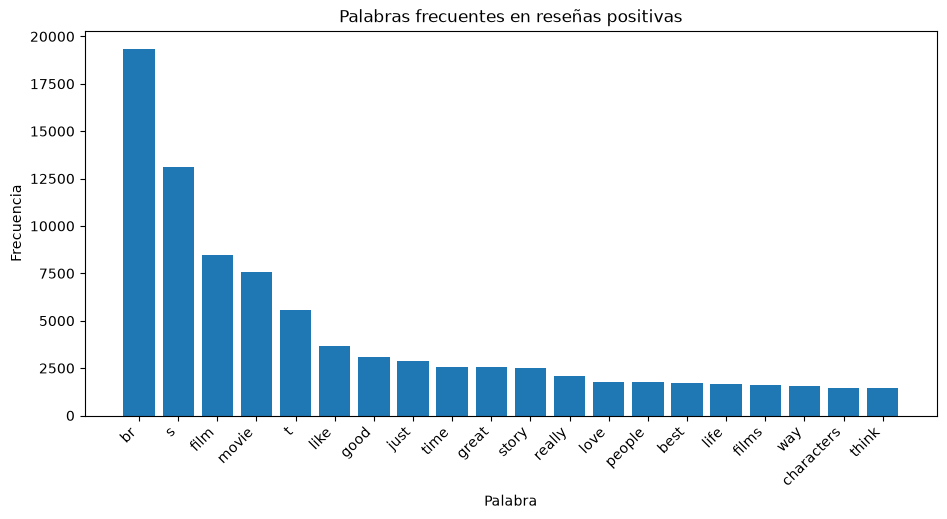

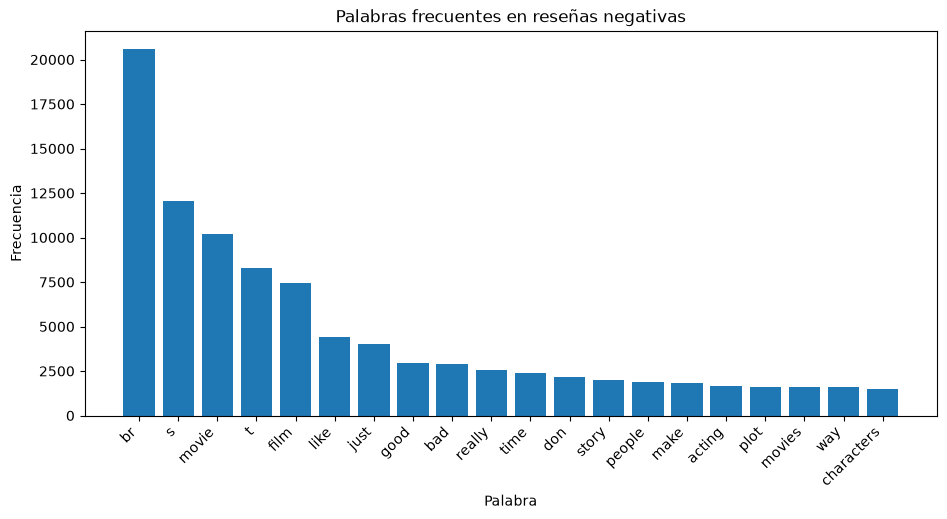

In [14]:
top_positive = get_top_words(
    df.loc[df["sentiment_label"] == "positive", TEXT_COL],
    n=20,
    remove_stopwords=True
)

top_negative = get_top_words(
    df.loc[df["sentiment_label"] == "negative", TEXT_COL],
    n=20,
    remove_stopwords=True
)

plot_top_words(
    top_positive,
    "Palabras frecuentes en reseñas positivas"
)

plot_top_words(
    top_negative,
    "Palabras frecuentes en reseñas negativas"
)

### Vocabulario y palabras raras

Si el vocabulario tiene $m$ términos, cada documento se representa con un vector de dimensión $m$.

En un corpus real:

- Un pequeño grupo de palabras aparece muchas veces.
- Una gran cantidad de palabras aparece muy pocas veces.
- Esto produce vectores de alta dimensión con muchos ceros.

Esa estructura se denomina **matriz dispersa**.

In [15]:
all_tokens = []

for text in df[TEXT_COL]:
    all_tokens.extend(simple_tokenize(text))

word_counts = Counter(all_tokens)

total_unique_words = len(word_counts)
words_once = [word for word, count in word_counts.items() if count == 1]
num_words_once = len(words_once)

vocabulary_summary = pd.DataFrame({
    "métrica": [
        "tokens totales",
        "palabras únicas",
        "palabras que aparecen una sola vez",
        "porcentaje del vocabulario con frecuencia 1"
    ],
    "valor": [
        len(all_tokens),
        total_unique_words,
        num_words_once,
        100 * num_words_once / total_unique_words
    ]
})

display(vocabulary_summary.round(2))
print("Ejemplos de palabras con frecuencia 1:")
print(words_once[:40])

,métrica,valor
0,tokens totales,2381850.00
1,palabras únicas,51380.00
2,palabras que aparecen una sola vez,19387.00
3,porcentaje del vocabulario con frecuencia 1,37.73


Ejemplos de palabras con frecuencia 1:
['hening', 'harts', 'ludvig', 'borga', 'jannetty', 'gunns', 'hardiest', 'brainbender', 'equational', 'kaos', 'nationally', 'crossword', 'belabor', 'funnybone', 'subversively', 'favela', 'mesa', 'twop', 'hunch', 'purgatorio', 'iffy', 'melfi', 'receptionists', 'infinnerty', 'infiniti', 'aaaand', 'patronized', 'sparticles', 'vibrating', 'teetering', 'swansons', 'stuttured', 'whithnail', 'skikkelig', 'gebrokkent', 'degression', 'aproved', 'grassy', 'coloric', 'mindstate']


## Ejercicio 2

1. Compare las palabras frecuentes de ambas clases.
2. ¿Cuáles aparecen en las dos listas?
3. ¿Por qué la frecuencia bruta no basta para determinar importancia?
4. ¿Qué efecto puede tener un vocabulario con miles de palabras raras?

In [16]:
# Solución Ejercicio 2
pos_words = dict(top_positive)
neg_words = dict(top_negative)
common = sorted(set(pos_words) & set(neg_words), key=lambda w: -(pos_words[w] + neg_words[w]))

comparison = pd.DataFrame({
    "palabra": common,
    "frec_positive": [pos_words[w] for w in common],
    "frec_negative": [neg_words[w] for w in common],
})
comparison["ratio_pos/neg"] = comparison["frec_positive"] / comparison["frec_negative"]
print(f"Palabras en ambas listas top-20 ({len(common)}):")
display(comparison.round(2))
print("Solo en positivas:", sorted(set(pos_words) - set(neg_words)))
print("Solo en negativas:", sorted(set(neg_words) - set(pos_words)))
print(f"Palabras con frecuencia 1: {num_words_once} de {total_unique_words} "
      f"({100 * num_words_once / total_unique_words:.1f}% del vocabulario)")


Palabras en ambas listas top-20 (14):


,palabra,frec_positive,frec_negative,ratio_pos/neg
0,br,19344,20603,0.94
1,s,13091,12031,1.09
2,movie,7556,10196,0.74
3,film,8464,7444,1.14
4,t,5581,8305,0.67
5,like,3650,4418,0.83
6,just,2874,4045,0.71
7,good,3109,2935,1.06
8,time,2578,2405,1.07
9,really,2101,2538,0.83


Solo en positivas: ['best', 'films', 'great', 'life', 'love', 'think']
Solo en negativas: ['acting', 'bad', 'don', 'make', 'movies', 'plot']
Palabras con frecuencia 1: 19387 de 51380 (37.7% del vocabulario)


### Respuesta Ejercicio 2

1. **Comparación:** de las 20 palabras más frecuentes (sin stop words) por clase, **14 se repiten** en ambas. Las exclusivas sí tienen carga de sentimiento: positivas → `great`, `best`, `love`, `life`, `films`, `think`; negativas → `bad`, `acting`, `plot`, `make`, `movies`, `don`.
2. **Palabras en ambas listas:** `br`, `s`, `movie`, `film`, `t`, `like`, `just`, `good`, `time`, `really`, `story`, `people`, `way`, `characters`. Varias son ruido: `br` es la etiqueta HTML `<br />`, y `s`/`t` son restos de contracciones (`it's`, `don't`).
3. **La frecuencia bruta no basta:** una palabra puede ser muy frecuente en ambas clases y no discriminar nada (`movie`, `film`, `way` tienen razón pos/neg ≈ 1). Incluso `good` aparece casi igual en negativas (2 935) que en positivas (3 109), porque se usa en "not good" o "good actors but…". La importancia depende de cuánto **diferencia** a las clases y del contexto, no de cuántas veces aparece.
4. **Vocabulario con miles de palabras raras:** el **37,7 %** del vocabulario (19 387 de 51 380 palabras) aparece una sola vez. Eso aumenta la dimensionalidad y la dispersidad de la matriz, gasta memoria, añade ruido (errores tipográficos, nombres propios) y favorece el sobreajuste, porque el modelo puede memorizar palabras que no generalizan. Por eso se usan `min_df` y `max_features`.


# 2. Normalización y limpieza

La limpieza busca reducir variaciones que no aportan al problema. No obstante, **limpiar más no siempre significa modelar mejor**.

Para análisis de sentimiento debemos tener especial cuidado con las negaciones:

> `not good` no significa lo mismo que `good`.

La limpieza aplicada será deliberadamente conservadora:

1. Minúsculas.
2. Eliminación de HTML y URLs.
3. Conversión de contracciones terminadas en `n't` a `not`.
4. Eliminación de caracteres no alfabéticos.
5. Eliminación de stop words, conservando negaciones.
6. Sin stemming ni lematización, para mantener el foco en BoW y TF-IDF.

In [17]:
NEGATIONS_TO_KEEP = {"no", "not", "nor", "never"}
CUSTOM_STOP_WORDS = set(ENGLISH_STOP_WORDS) - NEGATIONS_TO_KEEP


def clean_text(text):
    """Limpieza conservadora para análisis de sentimiento en inglés."""

    text = str(text).lower()

    # HTML y URLs
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Preservar la información de negación:
    # wasn't -> was not, didn't -> did not, isn't -> is not
    text = re.sub(r"n['’]t\b", " not", text)

    # Solo letras y espacios
    text = re.sub(r"[^a-z\s]", " ", text)

    tokens = text.split()

    tokens = [
        token for token in tokens
        if token not in CUSTOM_STOP_WORDS
    ]

    return " ".join(tokens)


df["review_clean"] = df[TEXT_COL].apply(clean_text)
df["num_words_clean"] = df["review_clean"].apply(lambda text: len(text.split()))

display(
    df[[TEXT_COL, "review_clean", "sentiment_label"]].head(8)
)

,review,review_clean,sentiment_label
0,"I really liked this Summerslam due to the look of the arena, the curtains and just the look overall was interesting to me for some reason. Anyways, this could have been one of ...",really liked summerslam look arena curtains just look overall interesting reason anyways best summerslam s wwf did not lex luger main event yokozuna s time ok huge fat man vs s...,positive
1,Not many television shows appeal to quite as many different kinds of fans like Farscape does...I know youngsters and 30/40+ years old;fans both Male and Female in as many diffe...,not television shows appeal quite different kinds fans like farscape does know youngsters years old fans male female different countries think just adore t v miniseries element...,positive
2,The film quickly gets to a major chase scene with ever increasing destruction. The first really bad thing is the guy hijacking Steven Seagal would have been beaten to pulp by S...,film quickly gets major chase scene increasing destruction really bad thing guy hijacking steven seagal beaten pulp seagal s driving probably ended premise movie like decided m...,negative
3,"Jane Austen would definitely approve of this one!<br /><br />Gwyneth Paltrow does an awesome job capturing the attitude of Emma. She is funny without being excessively silly, y...",jane austen definitely approve gwyneth paltrow does awesome job capturing attitude emma funny excessively silly elegant puts convincing british accent not british maybe m not b...,positive
4,"Expectations were somewhat high for me when I went to see this movie, after all I thought Steve Carell could do no wrong coming off of great movies like Anchorman, The 40 Year-...",expectations somewhat high went movie thought steve carell no wrong coming great movies like anchorman year old virgin little miss sunshine boy wrong ll start right movie certa...,negative
5,"I've watched this movie on a fairly regular basis for most of my life, and it never gets old. For all the snide remarks and insults (mostly from David Spade), ""Tommy Boy"" has a...",ve watched movie fairly regular basis life never gets old snide remarks insults david spade tommy boy giant heart s keeps movie funny years tommy callahan chris farley son big ...,positive
6,"For once a story of hope highlighted over the tragic reality our youth face. Favela Rising draws one into a scary, unsafe and unfair world and shows through beautiful color and...",story hope highlighted tragic reality youth face favela rising draws scary unsafe unfair world shows beautiful color moving music man dedicated friends choose not accept world ...,positive
7,"Okay, I didn't get the Purgatory thing the first time I watched this episode. It seemed like something significant was going on that I couldn't put my finger on. This time thos...",okay did not purgatory thing time watched episode like significant going not finger time costa mesa fires tv really caught attention helped just writing essay inferno let not d...,positive


,versión,promedio_palabras,mediana_palabras
0,original,231.88,173.0
1,limpia,112.39,83.0


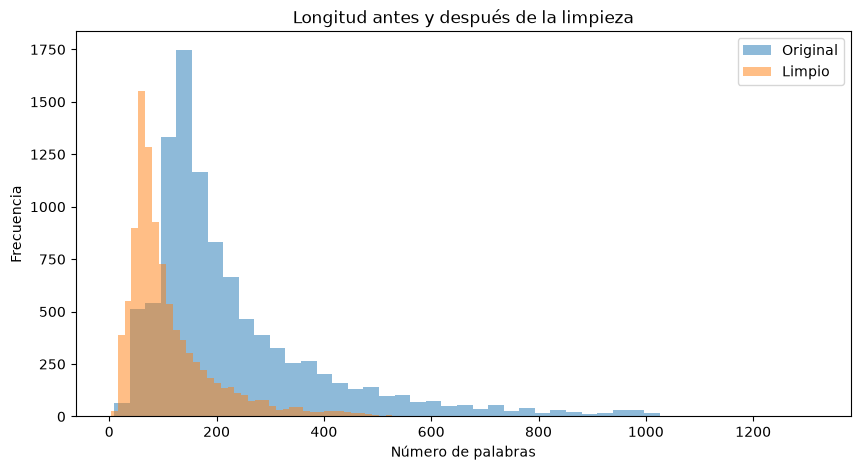

In [18]:
cleaning_summary = pd.DataFrame({
    "versión": ["original", "limpia"],
    "promedio_palabras": [
        df["num_words"].mean(),
        df["num_words_clean"].mean()
    ],
    "mediana_palabras": [
        df["num_words"].median(),
        df["num_words_clean"].median()
    ]
})

display(cleaning_summary.round(2))

plt.figure(figsize=(10, 5))
plt.hist(df["num_words"], bins=45, alpha=0.5, label="Original")
plt.hist(df["num_words_clean"], bins=45, alpha=0.5, label="Limpio")
plt.title("Longitud antes y después de la limpieza")
plt.xlabel("Número de palabras")
plt.ylabel("Frecuencia")
plt.legend()
plt.show()

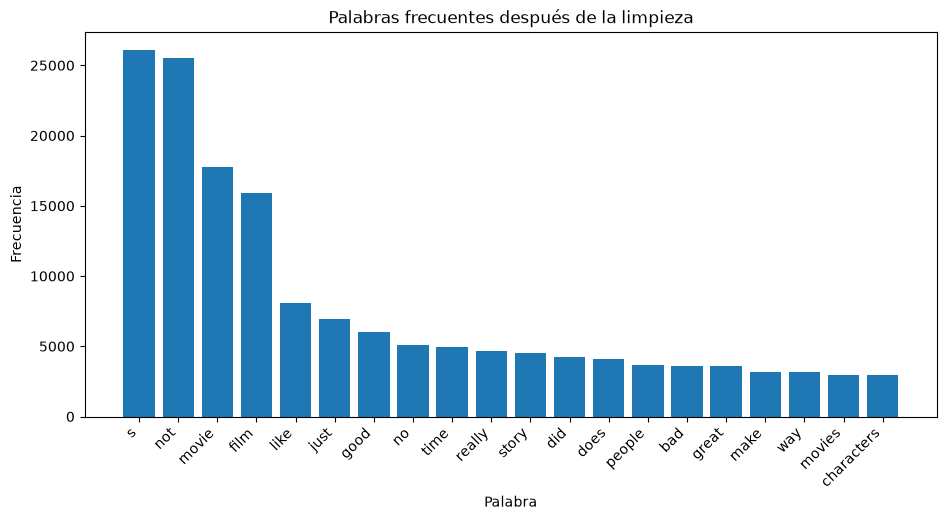

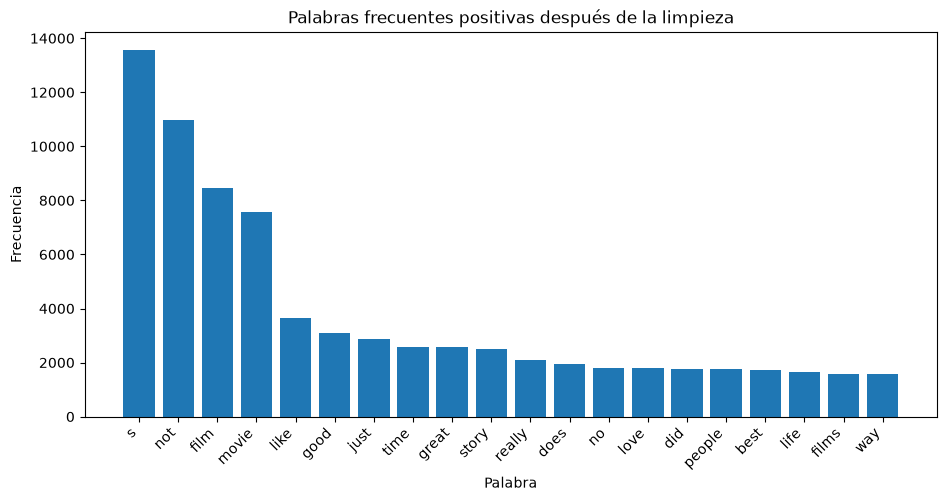

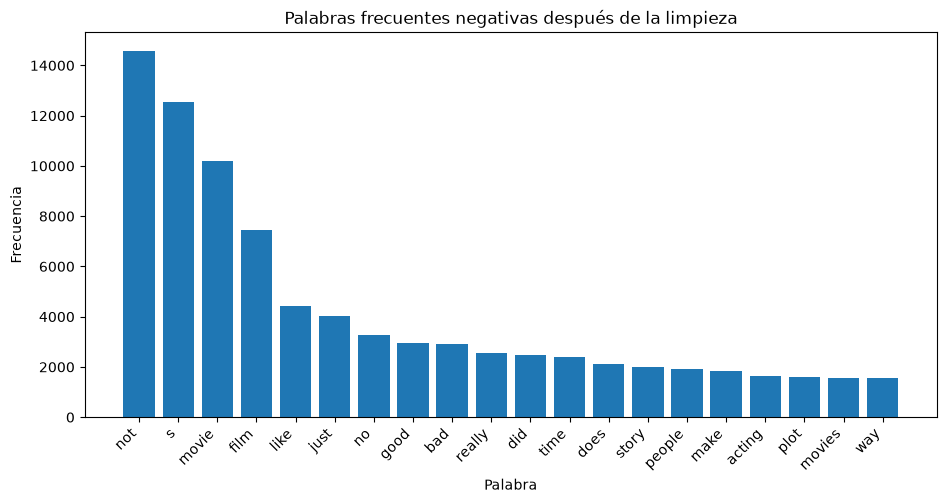

In [19]:
top_clean = get_top_words(
    df["review_clean"],
    n=20,
    remove_stopwords=False
)

top_clean_positive = get_top_words(
    df.loc[df["sentiment_label"] == "positive", "review_clean"],
    n=20,
    remove_stopwords=False
)

top_clean_negative = get_top_words(
    df.loc[df["sentiment_label"] == "negative", "review_clean"],
    n=20,
    remove_stopwords=False
)

plot_top_words(top_clean, "Palabras frecuentes después de la limpieza")
plot_top_words(
    top_clean_positive,
    "Palabras frecuentes positivas después de la limpieza"
)
plot_top_words(
    top_clean_negative,
    "Palabras frecuentes negativas después de la limpieza"
)

## Ejercicio 3

Seleccione cinco reseñas y compare el texto original con el limpio.

1. ¿Qué ruido desapareció?
2. ¿Qué información útil pudo perderse?
3. ¿Se conservaron las negaciones?
4. ¿Sería conveniente remover todas las stop words en cualquier tarea de NLP?

In [20]:
# Solución Ejercicio 3
sample = df.sample(5, random_state=RANDOM_STATE)
for idx, row in sample.iterrows():
    print(f"--- Reseña {idx} ({row['sentiment_label']}) ---")
    print("ORIGINAL:", row[TEXT_COL][:400], "...")
    print("LIMPIA  :", row["review_clean"][:400], "...")
    print()

# ¿Se conservan las negaciones?
neg_pattern = r"\b(not|no|never|nor)\b|n't"
has_neg_raw = df[TEXT_COL].str.lower().str.contains(neg_pattern, regex=True)
has_neg_clean = df["review_clean"].str.contains(r"\b(not|no|never|nor)\b", regex=True)
print("Reseñas con negación en texto original:", has_neg_raw.sum())
print("Reseñas con negación en texto limpio  :", has_neg_clean.sum())
print("Ejemplo:", clean_text("I didn't like it, it wasn't good <br /> at all!!! 10/10 :)"))


--- Reseña 5753 (negative) ---
ORIGINAL: The only reason I gave this movie a 2 and not a 1 was because for some reason I felt compelled to finish it out! Basically, I wanted to see if there were going to be any aliens, any UFO's, anything at all suggested by the title of the movie, the cover of the movie and the beginning of the movie! I was very disappointed to see religion being thrown into the mix the way that it was. This could have  ...
LIMPIA  : reason gave movie not reason felt compelled finish basically wanted going aliens ufo s suggested title movie cover movie beginning movie disappointed religion thrown mix way used movie s advantage felt instead movie trying send subliminal messages finally big cast s wardrobe distracted number different extremely bright shirts character new scene began wonder movie not really supposed classified po ...

--- Reseña 7623 (negative) ---
ORIGINAL: The movie's storyline is pat and quaint. Two women travel through the middle east and discover th

Reseñas con negación en texto original: 8746
Reseñas con negación en texto limpio  : 8744
Ejemplo: did not like not good


### Respuesta Ejercicio 3

1. **Ruido que desapareció:** etiquetas HTML (`<br /><br />`), puntuación (`!`, `...`, `/`), números (el "2" y el "1" de la primera reseña), mayúsculas y stop words (`the`, `this`, `was`, `a`…).
2. **Información útil que pudo perderse:**
   - Los **números** con significado evaluativo: "gave this movie a **2** and not a **1**" queda como "gave movie not reason".
   - Énfasis y emoción: `!!!`, emoticonos (`:)`), mayúsculas ("CRUD").
   - Algunas stop words con valor de sentimiento o de contraste (`but`, `very`, `too`, `only`).
   - Nombres propios unidos o partidos (`ufo s`, `movie s`), y el orden de las palabras.
3. **Negaciones:** sí se conservan. `didn't` → `did not`, y `not`, `no`, `never`, `nor` se excluyeron de la lista de stop words (8 746 reseñas con negación en el original frente a 8 744 en el texto limpio). Ejemplo: `"I didn't like it, it wasn't good"` → `"did not like not good"`.
4. **¿Remover siempre las stop words?** No. Depende de la tarea: en sentimiento, `not`, `no`, `but`, `very` y `too` cambian el significado; en traducción, preguntas y respuestas, resúmenes o modelos de lenguaje, las stop words son esenciales para la gramática y el contexto. Quitarlas sirve sobre todo para análisis temático o de recuperación por palabras clave, y aun así conviene validarlo empíricamente. En este notebook, de hecho, el texto limpio rindió un poco **peor** (ver Ejercicio 6).


# 3. División de entrenamiento y prueba

Usaremos exactamente la misma partición para todos los experimentos. Así, cualquier diferencia se debe principalmente a:

- La representación: BoW o TF-IDF.
- El uso de texto original o limpio.

La opción `stratify=y` mantiene proporciones de clase similares en entrenamiento y prueba.

In [21]:
X_raw = df[TEXT_COL]
X_clean = df["review_clean"]
y = df[TARGET_COL]

(
    X_raw_train,
    X_raw_test,
    X_clean_train,
    X_clean_test,
    y_train,
    y_test
) = train_test_split(
    X_raw,
    X_clean,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

split_summary = pd.DataFrame({
    "conjunto": ["train", "test"],
    "documentos": [len(y_train), len(y_test)],
    "proporción_positiva": [y_train.mean(), y_test.mean()]
})

display(split_summary.round(3))

,conjunto,documentos,proporción_positiva
0,train,7982,0.505
1,test,1996,0.505


# 4. Bag of Words

## 4.1 Idea central

Sea un vocabulario:

$$
V=\{t_1,t_2,\ldots,t_m\}
$$

Para cada documento $d_i$, Bag of Words construye un vector:

$$
\mathbf{x}_i =
[x_{i1},x_{i2},\ldots,x_{im}]
$$

donde:

$$
x_{ij}=\operatorname{count}(t_j,d_i)
$$

Es decir, cada posición almacena cuántas veces aparece el término $t_j$ en el documento $d_i$.

Para $n$ documentos obtenemos una matriz documento–término:

$$
X \in \mathbb{N}^{n \times m}
$$

- Las filas representan documentos.
- Las columnas representan palabras.
- Las celdas representan conteos.

## 4.2 Supuesto de la “bolsa”

BoW ignora el orden y la estructura gramatical. Dos textos con las mismas palabras y frecuencias reciben el mismo vector aunque expresen ideas diferentes.


## 4.3 Ejemplo pequeño paso a paso

Usaremos las mismas tres reseñas cortas de la versión anterior:

1. `This movie is very scary and long`
2. `This movie is not scary and is slow`
3. `This movie is spooky and good`

Primero se construye el vocabulario y luego se cuentan los términos de cada documento.

In [22]:
toy_documents = [
    "This movie is very scary and long",
    "This movie is not scary and is slow",
    "This movie is spooky and good"
]

toy_bow = CountVectorizer(lowercase=True)
toy_bow_matrix = toy_bow.fit_transform(toy_documents)

toy_bow_df = pd.DataFrame(
    toy_bow_matrix.toarray(),
    columns=toy_bow.get_feature_names_out(),
    index=["Review 1", "Review 2", "Review 3"]
)

print("Vocabulario:")
print(toy_bow.get_feature_names_out())

display(toy_bow_df)

Vocabulario:
['and' 'good' 'is' 'long' 'movie' 'not' 'scary' 'slow' 'spooky' 'this'
 'very']


,and,good,is,long,movie,not,scary,slow,spooky,this,very
Review 1,1,0,1,1,1,0,1,0,0,1,1
Review 2,1,0,2,0,1,1,1,1,0,1,0
Review 3,1,1,1,0,1,0,0,0,1,1,0


### Cómo leer la matriz

- `is = 2` en la segunda reseña porque aparece dos veces.
- `slow = 1` solamente en la segunda.
- `spooky = 1` solamente en la tercera.
- La mayoría de las celdas son cero.

La densidad de una matriz se define como:

$$
\operatorname{densidad}(X)=
\frac{\text{número de valores distintos de cero}}
{\text{número total de celdas}}
$$

Una densidad baja indica una matriz muy dispersa.


In [23]:
non_zero_values = toy_bow_matrix.nnz
total_cells = toy_bow_matrix.shape[0] * toy_bow_matrix.shape[1]
density = non_zero_values / total_cells

print("Forma de la matriz:", toy_bow_matrix.shape)
print("Valores distintos de cero:", non_zero_values)
print("Densidad:", round(density, 3))
print("Dispersidad:", round(1 - density, 3))

Forma de la matriz: (3, 11)
Valores distintos de cero: 20
Densidad: 0.606
Dispersidad: 0.394


## 4.4 ¿Qué información pierde BoW?

Compare:

- `good movie not boring`
- `boring movie not good`

Ambas oraciones contienen exactamente las mismas palabras una vez. Por tanto, BoW genera el mismo vector.

Este ejemplo muestra que contar términos no equivale a comprender el lenguaje.

In [24]:
order_examples = [
    "good movie not boring",
    "boring movie not good"
]

order_vectorizer = CountVectorizer()
order_matrix = order_vectorizer.fit_transform(order_examples)

display(
    pd.DataFrame(
        order_matrix.toarray(),
        columns=order_vectorizer.get_feature_names_out(),
        index=["Texto A", "Texto B"]
    )
)

print(
    "¿Los vectores son iguales?",
    np.array_equal(order_matrix.toarray()[0], order_matrix.toarray()[1])
)

,boring,good,movie,not
Texto A,1,1,1,1
Texto B,1,1,1,1


¿Los vectores son iguales? True


## 4.5 Parámetros importantes de `CountVectorizer`

En este notebook utilizaremos:

- `max_features=5000`: limita el vocabulario a las características más frecuentes.
- `min_df=2`: elimina términos que aparecen en menos de dos documentos.
- `lowercase=True`: normaliza mayúsculas y minúsculas.
- `ngram_range=(1,1)`: utiliza solamente palabras individuales.

Estas decisiones controlan la dimensionalidad y reducen parte del ruido.

## 4.6 Entrenamiento y evaluación reutilizable

Para comparar de forma justa los experimentos utilizaremos:

- El mismo clasificador.
- La misma partición train/test.
- Las mismas métricas.
- El vocabulario aprendido únicamente con entrenamiento.

Ajustar el vectorizador antes de dividir los datos produciría **data leakage**.

In [25]:
def matrix_density(matrix):
    return matrix.nnz / (matrix.shape[0] * matrix.shape[1])


def train_and_evaluate(
    vectorizer,
    X_train_text,
    X_test_text,
    y_train,
    y_test,
    experiment_name,
    representation,
    text_version
):
    # El vocabulario se aprende únicamente con train
    X_train_matrix = vectorizer.fit_transform(X_train_text)
    X_test_matrix = vectorizer.transform(X_test_text)

    model = LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    )
    model.fit(X_train_matrix, y_train)

    y_pred = model.predict(X_test_matrix)
    y_prob = model.predict_proba(X_test_matrix)[:, 1]

    result = {
        "experiment": experiment_name,
        "representation": representation,
        "text_version": text_version,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1": f1_score(y_test, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_prob),
        "vocabulary_size": len(vectorizer.get_feature_names_out()),
        "train_density": matrix_density(X_train_matrix),
        "vectorizer": vectorizer,
        "model": model,
        "X_train_matrix": X_train_matrix,
        "X_test_matrix": X_test_matrix,
        "test_index": X_test_text.index.to_numpy(),
        "y_true": np.asarray(y_test),
        "y_pred": y_pred,
        "y_prob": y_prob
    }

    print(f"\n{experiment_name}")
    print("-" * len(experiment_name))
    print("Forma train:", X_train_matrix.shape)
    print("Forma test:", X_test_matrix.shape)
    print("Tamaño vocabulario:", result["vocabulary_size"])
    print("Densidad train:", round(result["train_density"], 6))
    print(classification_report(y_test, y_pred, digits=4))

    return result

In [26]:
all_results = []

bow_raw_result = train_and_evaluate(
    vectorizer=CountVectorizer(
        max_features=5000,
        min_df=2,
        ngram_range=(1, 1)
    ),
    X_train_text=X_raw_train,
    X_test_text=X_raw_test,
    y_train=y_train,
    y_test=y_test,
    experiment_name="BoW - texto original",
    representation="BoW",
    text_version="original"
)

bow_clean_result = train_and_evaluate(
    vectorizer=CountVectorizer(
        max_features=5000,
        min_df=2,
        ngram_range=(1, 1)
    ),
    X_train_text=X_clean_train,
    X_test_text=X_clean_test,
    y_train=y_train,
    y_test=y_test,
    experiment_name="BoW - texto limpio",
    representation="BoW",
    text_version="limpio"
)

all_results.extend([bow_raw_result, bow_clean_result])


BoW - texto original
--------------------
Forma train: (7982, 5000)
Forma test: (1996, 5000)
Tamaño vocabulario: 5000
Densidad train: 0.023612
              precision    recall  f1-score   support

           0     0.8621    0.8473    0.8547       989
           1     0.8525    0.8669    0.8597      1007

    accuracy                         0.8572      1996
   macro avg     0.8573    0.8571    0.8572      1996
weighted avg     0.8573    0.8572    0.8572      1996




BoW - texto limpio
------------------
Forma train: (7982, 5000)
Forma test: (1996, 5000)
Tamaño vocabulario: 5000
Densidad train: 0.014129
              precision    recall  f1-score   support

           0     0.8548    0.8453    0.8500       989
           1     0.8497    0.8590    0.8543      1007

    accuracy                         0.8522      1996
   macro avg     0.8523    0.8521    0.8522      1996
weighted avg     0.8522    0.8522    0.8522      1996



## Ejercicio 4

1. ¿Cuál versión de BoW obtuvo mejor F1?
2. ¿La limpieza redujo el tamaño efectivo del vocabulario?
3. ¿Por qué la matriz sigue siendo dispersa?
4. ¿Qué ventaja ofrece BoW frente al texto original?
5. ¿Qué información lingüística continúa perdiéndose?

In [27]:
# Solución Ejercicio 4
bow_results = pd.DataFrame([
    {k: r[k] for k in ["experiment", "accuracy", "f1", "roc_auc", "vocabulary_size", "train_density"]}
    for r in all_results if r["representation"] == "BoW"
]).sort_values("f1", ascending=False)
display(bow_results.round(4))

# Vocabulario efectivo antes del recorte max_features=5000
vocab_raw = len(CountVectorizer(min_df=2).fit(X_raw_train).vocabulary_)
vocab_clean = len(CountVectorizer(min_df=2).fit(X_clean_train).vocabulary_)
print("Vocabulario (min_df=2) texto original:", vocab_raw)
print("Vocabulario (min_df=2) texto limpio  :", vocab_clean)
print("Reducción:", f"{100 * (1 - vocab_clean / vocab_raw):.1f}%")


,experiment,accuracy,f1,roc_auc,vocabulary_size,train_density
0,BoW - texto original,0.8572,0.8597,0.9285,5000,0.0236
1,BoW - texto limpio,0.8522,0.8543,0.9235,5000,0.0141


Vocabulario (min_df=2) texto original: 27495
Vocabulario (min_df=2) texto limpio  : 26845
Reducción: 2.4%


### Respuesta Ejercicio 4

1. **Mejor BoW según F1:** **BoW con texto original** (F1 = 0,8597) frente a BoW con texto limpio (F1 = 0,8543).
2. **Reducción del vocabulario:** sí, pero poco. Con `min_df=2`, el vocabulario de train pasa de **27 495** a **26 845** términos (−2,4 %). Como ambos modelos se recortan a `max_features=5000`, el tamaño final es igual (5 000). Lo que sí cambió fue la densidad: 0,0236 → 0,0141, porque se eliminaron stop words muy frecuentes.
3. **¿Por qué sigue siendo dispersa?** Cada reseña usa unas decenas o cientos de palabras de un vocabulario de 5 000. Más del 97–98 % de las celdas son cero, y eso no cambia al limpiar: es una propiedad del lenguaje (ley de Zipf), no del ruido.
4. **Ventaja frente al texto original:** convierte texto de longitud variable en un **vector numérico de dimensión fija**, que sirve como entrada de modelos de machine learning y álgebra lineal. Además es simple, rápido, escalable (matrices *sparse*) e interpretable: cada columna es una palabra.
5. **Información que se sigue perdiendo:** el **orden** de las palabras ("good movie not boring" y "boring movie not good" dan el mismo vector), el alcance de la negación, la sintaxis, el contexto, la semántica (sinónimos como `excellent`/`wonderful` son columnas independientes), la polisemia, el sarcasmo y las palabras fuera del vocabulario.


# 5. TF-IDF

BoW asigna más peso a una palabra cuando aparece más veces. El problema es que algunas palabras son frecuentes en casi todos los documentos y, por tanto, ayudan poco a distinguirlos.

TF-IDF combina dos ideas.

## 5.1 Term Frequency

La frecuencia del término mide cuánto aparece un término $t$ dentro de un documento $d$:

$$
\operatorname{tf}(t,d)=\operatorname{count}(t,d)
$$

Una variante normalizada divide por la cantidad total de términos del documento:

$$
\operatorname{tf}_{norm}(t,d)=
\frac{\operatorname{count}(t,d)}
{\sum_{t'}\operatorname{count}(t',d)}
$$

## 5.2 Document Frequency

$$
\operatorname{df}(t)=
\left|\{d \in D:t\in d\}\right|
$$

`df` es el número de documentos que contienen el término. No es el número total de apariciones en toda la colección.

## 5.3 Inverse Document Frequency

La versión suavizada utilizada por `scikit-learn` es:

$$
\operatorname{idf}(t)=
\log\left(
\frac{1+N}{1+\operatorname{df}(t)}
\right)+1
$$

donde $N$ es el número total de documentos.

- Si un término aparece en casi todos los documentos, su IDF es pequeño.
- Si aparece en pocos documentos, su IDF es mayor.

## 5.4 Peso final

$$
\operatorname{tfidf}(t,d)=
\operatorname{tf}(t,d)\times \operatorname{idf}(t)
$$

Finalmente, `TfidfVectorizer` aplica por defecto normalización $L_2$ a cada vector:

$$
\|\mathbf{x}_d\|_2=1
$$

## 5.5 Ejemplo con el mismo corpus pequeño

Calcularemos TF-IDF sobre las tres reseñas anteriores. Observe que términos presentes en todos los documentos, como `movie` o `is`, reciben menos peso que términos distintivos como `slow`, `spooky` o `good`.

In [28]:
toy_tfidf = TfidfVectorizer(lowercase=True)
toy_tfidf_matrix = toy_tfidf.fit_transform(toy_documents)

toy_tfidf_df = pd.DataFrame(
    toy_tfidf_matrix.toarray(),
    columns=toy_tfidf.get_feature_names_out(),
    index=["Review 1", "Review 2", "Review 3"]
)

display(toy_tfidf_df.round(3))

,and,good,is,long,movie,not,scary,slow,spooky,this,very
Review 1,0.296,0.000,0.296,0.502,0.296,0.000,0.382,0.000,0.000,0.296,0.502
Review 2,0.264,0.000,0.527,0.000,0.264,0.446,0.339,0.446,0.000,0.264,0.000
Review 3,0.321,0.543,0.321,0.000,0.321,0.000,0.000,0.000,0.543,0.321,0.000


In [29]:
toy_idf_df = pd.DataFrame({
    "término": toy_tfidf.get_feature_names_out(),
    "document_frequency": np.asarray(
        (toy_tfidf_matrix > 0).sum(axis=0)
    ).ravel(),
    "idf": toy_tfidf.idf_
}).sort_values(["idf", "término"])

display(toy_idf_df.round(3))

,término,document_frequency,idf
0,and,3,1.000
2,is,3,1.000
4,movie,3,1.000
9,this,3,1.000
6,scary,2,1.288
1,good,1,1.693
3,long,1,1.693
5,not,1,1.693
7,slow,1,1.693
8,spooky,1,1.693


### Interpretación

- `movie` aparece en los tres documentos, por lo que su IDF es bajo.
- `scary` aparece en dos documentos, por lo que tiene un IDF intermedio.
- `slow`, `spooky`, `good`, `long`, `not` y `very` aparecen en uno, por lo que tienen un IDF mayor.
- TF-IDF no descubre semántica: únicamente repondera conteos según su distribución documental.

## 5.6 Cálculo manual de una palabra

Para un corpus de $N=3$ documentos, si `slow` aparece en un solo documento:

$$
\operatorname{idf}(\text{slow})=
\log\left(
\frac{1+3}{1+1}
\right)+1
=
\log(2)+1
$$

Si aparece una vez en la segunda reseña:

$$
\operatorname{tfidf}(\text{slow},d_2)
=
1 \times \left(\log(2)+1\right)
$$

Después, el vector completo se normaliza. Por eso el valor final mostrado por `scikit-learn` es menor que el peso sin normalizar.


In [30]:
N = len(toy_documents)
df_slow = 1
tf_slow_review_2 = 1

idf_slow_manual = np.log((1 + N) / (1 + df_slow)) + 1
tfidf_before_normalization = tf_slow_review_2 * idf_slow_manual

print("IDF suavizado de 'slow':", round(idf_slow_manual, 4))
print(
    "TF-IDF antes de normalizar:",
    round(tfidf_before_normalization, 4)
)

slow_col = list(toy_tfidf.get_feature_names_out()).index("slow")
print(
    "TF-IDF final de 'slow' en Review 2:",
    round(toy_tfidf_matrix.toarray()[1, slow_col], 4)
)

IDF suavizado de 'slow': 1.6931
TF-IDF antes de normalizar: 1.6931
TF-IDF final de 'slow' en Review 2: 0.4463


## 5.7 Entrenamiento con TF-IDF

Mantendremos los mismos límites de vocabulario utilizados con BoW:

- `max_features=5000`
- `min_df=2`
- `ngram_range=(1,1)`

Así la comparación se concentra en la ponderación y no en cambios arbitrarios del espacio de características.

In [31]:
tfidf_raw_result = train_and_evaluate(
    vectorizer=TfidfVectorizer(
        max_features=5000,
        min_df=2,
        ngram_range=(1, 1)
    ),
    X_train_text=X_raw_train,
    X_test_text=X_raw_test,
    y_train=y_train,
    y_test=y_test,
    experiment_name="TF-IDF - texto original",
    representation="TF-IDF",
    text_version="original"
)

tfidf_clean_result = train_and_evaluate(
    vectorizer=TfidfVectorizer(
        max_features=5000,
        min_df=2,
        ngram_range=(1, 1)
    ),
    X_train_text=X_clean_train,
    X_test_text=X_clean_test,
    y_train=y_train,
    y_test=y_test,
    experiment_name="TF-IDF - texto limpio",
    representation="TF-IDF",
    text_version="limpio"
)

all_results.extend([tfidf_raw_result, tfidf_clean_result])


TF-IDF - texto original
-----------------------
Forma train: (7982, 5000)
Forma test: (1996, 5000)
Tamaño vocabulario: 5000
Densidad train: 0.023612
              precision    recall  f1-score   support

           0     0.8951    0.8625    0.8785       989
           1     0.8696    0.9007    0.8849      1007

    accuracy                         0.8818      1996
   macro avg     0.8823    0.8816    0.8817      1996
weighted avg     0.8822    0.8818    0.8817      1996




TF-IDF - texto limpio
---------------------
Forma train: (7982, 5000)
Forma test: (1996, 5000)
Tamaño vocabulario: 5000
Densidad train: 0.014129
              precision    recall  f1-score   support

           0     0.8824    0.8493    0.8655       989
           1     0.8573    0.8888    0.8727      1007

    accuracy                         0.8692      1996
   macro avg     0.8698    0.8691    0.8691      1996
weighted avg     0.8697    0.8692    0.8692      1996



## 5.8 ¿Qué términos considera comunes o distintivos?

Podemos inspeccionar el IDF aprendido con el conjunto de entrenamiento:

- IDF bajo: términos presentes en muchos documentos.
- IDF alto: términos presentes en pocos documentos.

Un IDF alto no garantiza relevancia semántica; el término también podría ser raro o ruidoso.

In [32]:
idf_vectorizer = tfidf_clean_result["vectorizer"]

idf_table = pd.DataFrame({
    "término": idf_vectorizer.get_feature_names_out(),
    "idf": idf_vectorizer.idf_
})

print("Términos con menor IDF:")
display(idf_table.nsmallest(15, "idf").round(3))

print("Términos con mayor IDF dentro del vocabulario seleccionado:")
display(idf_table.nlargest(15, "idf").round(3))

Términos con menor IDF:


,término,idf
3030,not,1.201
2916,movie,1.485
1671,film,1.588
2565,like,1.773
2400,just,1.873
1893,good,1.935
4512,time,2.057
3009,no,2.105
3560,really,2.177
4234,story,2.225


Términos con mayor IDF dentro del vocabulario seleccionado:


,término,idf
297,azumi,8.599
1280,dominick,8.599
1814,gandhi,8.376
2405,kahn,8.376
1962,gypo,8.193
2722,marlow,8.039
3740,rockne,8.039
387,bettie,7.906
1048,custer,7.906
1615,fassbinder,7.906


## Ejercicio 5

1. Explique la diferencia entre TF, DF e IDF.
2. ¿Por qué `df` no es igual a la frecuencia total de una palabra?
3. ¿Qué palabras del ejemplo reciben menor IDF?
4. ¿TF-IDF comprende el significado de `excellent` y `wonderful`?
5. Compare BoW y TF-IDF usando F1 y ROC-AUC.

In [33]:
# Solución Ejercicio 5
print("Ejemplo de juguete: términos con menor IDF")
display(toy_idf_df.nsmallest(5, "idf").round(3))

# ¿df == frecuencia total? Comparación en el vocabulario real
vec = tfidf_clean_result["vectorizer"]
counts = CountVectorizer(vocabulary=vec.vocabulary_).fit_transform(X_clean_train)
freq_vs_df = pd.DataFrame({
    "término": vec.get_feature_names_out(),
    "frecuencia_total": np.asarray(counts.sum(axis=0)).ravel(),
    "document_frequency": np.asarray((counts > 0).sum(axis=0)).ravel(),
}).nlargest(8, "frecuencia_total")
display(freq_vs_df)

# ¿TF-IDF entiende que excellent ~ wonderful?
from sklearn.metrics.pairwise import cosine_similarity
pair = vec.transform(["excellent", "wonderful"])
print("Similitud coseno TF-IDF entre 'excellent' y 'wonderful':",
      cosine_similarity(pair[0], pair[1])[0, 0])

display(pd.DataFrame([{k: r[k] for k in ["experiment", "representation", "f1", "roc_auc"]} for r in all_results]).round(4))


Ejemplo de juguete: términos con menor IDF


,término,document_frequency,idf
0,and,3,1.000
2,is,3,1.000
4,movie,3,1.000
9,this,3,1.000
6,scary,2,1.288


,término,frecuencia_total,document_frequency
3030,not,20550,6531
2916,movie,14360,4914
1671,film,12673,4434
2565,like,6488,3686
2400,just,5531,3334
1893,good,4831,3133
3009,no,4102,2642
4512,time,4036,2772


Similitud coseno TF-IDF entre 'excellent' y 'wonderful': 0.0


,experiment,representation,f1,roc_auc
0,BoW - texto original,BoW,0.8597,0.9285
1,BoW - texto limpio,BoW,0.8543,0.9235
2,TF-IDF - texto original,TF-IDF,0.8849,0.9506
3,TF-IDF - texto limpio,TF-IDF,0.8727,0.9460


### Respuesta Ejercicio 5

1. **TF, DF e IDF:**
   - **TF** (*term frequency*): cuántas veces aparece el término *t* **dentro de un documento** *d*. Es local al documento.
   - **DF** (*document frequency*): en **cuántos documentos** del corpus aparece *t* al menos una vez. Es global.
   - **IDF** (*inverse document frequency*): $\mathrm{idf}(t)=\ln\frac{1+N}{1+df(t)}+1$ en sklearn. Es alto para términos raros/distintivos y bajo para términos presentes en casi todos los documentos. TF-IDF = TF × IDF, normalizado L2.
2. **`df` ≠ frecuencia total:** df cuenta documentos, no apariciones; una reseña que dice "not" 10 veces suma 10 a la frecuencia total pero solo 1 a df. En train, `not` aparece **20 550 veces** pero en **6 531 documentos**; `movie`, 14 360 veces en 4 914 documentos.
3. **Menor IDF en el ejemplo:** `and`, `is`, `movie` y `this` (están en los 3 documentos, df = 3 → IDF = 1,0); después `scary` (df = 2, IDF = 1,288). Términos como `slow`, `spooky` o `good` (df = 1) tienen el IDF máximo (1,693).
4. **¿TF-IDF entiende `excellent` y `wonderful`?** No. Son dos columnas ortogonales: la similitud coseno entre sus vectores TF-IDF es **0,0**. TF-IDF solo pondera frecuencias; no sabe que son sinónimos. El modelo aprende que ambas son positivas solo porque cada una aparece por separado en reseñas positivas. Para capturar semántica se necesitan *embeddings* (word2vec, GloVe, BERT).
5. **BoW vs TF-IDF:** TF-IDF supera a BoW en ambas versiones del texto.

| Texto | F1 BoW | F1 TF-IDF | ROC-AUC BoW | ROC-AUC TF-IDF |
|---|---:|---:|---:|---:|
| original | 0,8597 | **0,8849** | 0,9285 | **0,9506** |
| limpio | 0,8543 | 0,8727 | 0,9235 | 0,9460 |

La mejora es de ~+2,5 puntos de F1 y ~+2,2 puntos de ROC-AUC: reducir el peso de palabras ubicuas y normalizar por longitud de la reseña ayuda al clasificador lineal.


# 6. Comparación global

Se comparan cuatro experimentos:

1. BoW con texto original.
2. BoW con texto limpio.
3. TF-IDF con texto original.
4. TF-IDF con texto limpio.

Las métricas principales son:

- **Accuracy:** proporción total de aciertos.
- **Precision:** cuántas predicciones positivas fueron correctas.
- **Recall:** cuántos positivos reales fueron encontrados.
- **F1:** media armónica de precision y recall.
- **ROC-AUC:** capacidad de ordenar positivos por encima de negativos usando probabilidades.

In [34]:
metric_columns = [
    "experiment",
    "representation",
    "text_version",
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "vocabulary_size",
    "train_density"
]

results_df = pd.DataFrame([
    {column: result[column] for column in metric_columns}
    for result in all_results
])

results_df = results_df.sort_values(
    "f1",
    ascending=False
).reset_index(drop=True)

display(results_df.round(4))

,experiment,representation,text_version,accuracy,precision,recall,f1,roc_auc,vocabulary_size,train_density
0,TF-IDF - texto original,TF-IDF,original,0.8818,0.8696,0.9007,0.8849,0.9506,5000,0.0236
1,TF-IDF - texto limpio,TF-IDF,limpio,0.8692,0.8573,0.8888,0.8727,0.9460,5000,0.0141
2,BoW - texto original,BoW,original,0.8572,0.8525,0.8669,0.8597,0.9285,5000,0.0236
3,BoW - texto limpio,BoW,limpio,0.8522,0.8497,0.8590,0.8543,0.9235,5000,0.0141


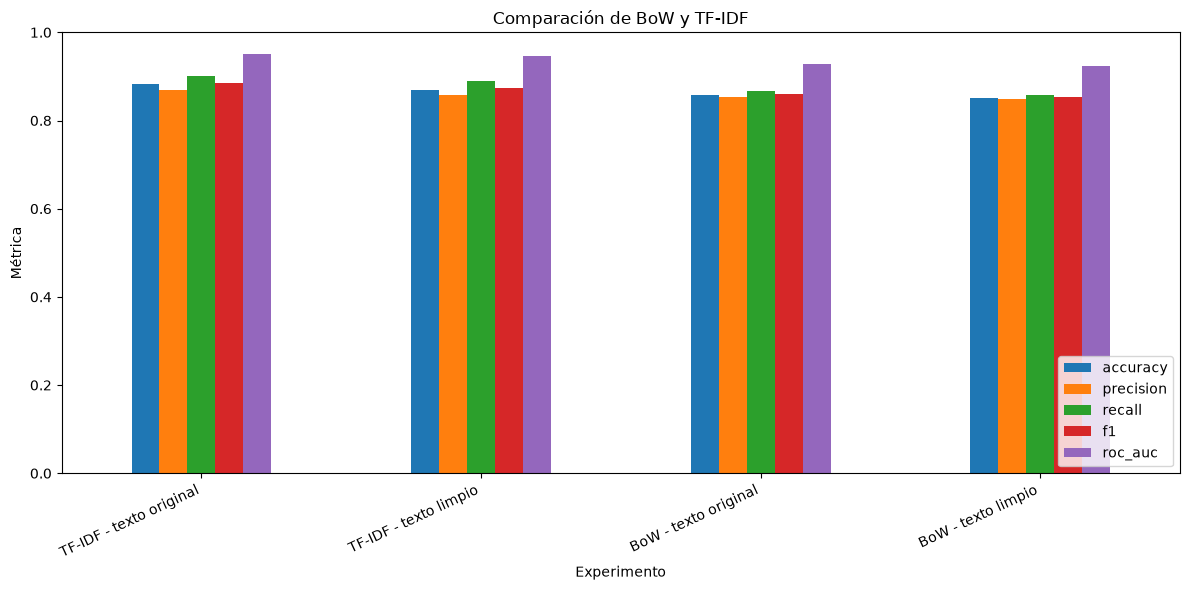

In [35]:
metrics_to_plot = ["accuracy", "precision", "recall", "f1", "roc_auc"]

plot_df = results_df.set_index("experiment")[metrics_to_plot]

ax = plot_df.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Comparación de BoW y TF-IDF")
ax.set_xlabel("Experimento")
ax.set_ylabel("Métrica")
ax.set_ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [36]:
best_result = max(all_results, key=lambda result: result["f1"])

best_summary = {
    key: best_result[key]
    for key in [
        "experiment",
        "representation",
        "text_version",
        "accuracy",
        "precision",
        "recall",
        "f1",
        "roc_auc",
        "vocabulary_size"
    ]
}

print("Mejor experimento según F1:")
display(pd.DataFrame([best_summary]).round(4))

Mejor experimento según F1:


,experiment,representation,text_version,accuracy,precision,recall,f1,roc_auc,vocabulary_size
0,TF-IDF - texto original,TF-IDF,original,0.8818,0.8696,0.9007,0.8849,0.9506,5000


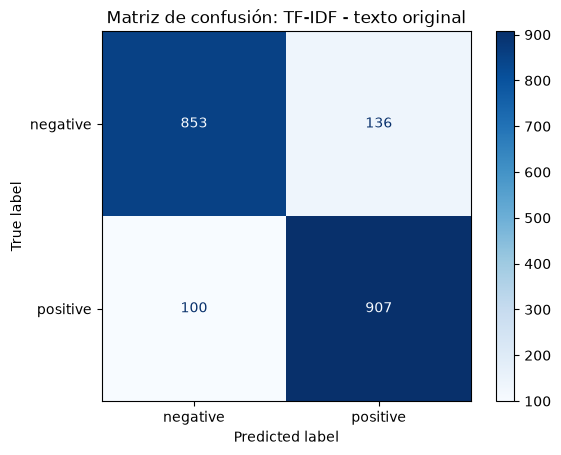

In [37]:
ConfusionMatrixDisplay.from_predictions(
    best_result["y_true"],
    best_result["y_pred"],
    display_labels=["negative", "positive"],
    cmap="Blues",
    values_format="d"
)

plt.title(f"Matriz de confusión: {best_result['experiment']}")
plt.show()

## Ejercicio 6

1. ¿Cuál fue el mejor método según F1?
2. ¿Cuál fue el mejor según ROC-AUC?
3. ¿La limpieza mejoró ambas representaciones?
4. ¿Las diferencias son grandes o pequeñas?
5. ¿Qué representación escogería como baseline y por qué?

In [38]:
# Solución Ejercicio 6
print("Mejor según F1     :", results_df.loc[results_df["f1"].idxmax(), "experiment"])
print("Mejor según ROC-AUC:", results_df.loc[results_df["roc_auc"].idxmax(), "experiment"])

pivot = results_df.pivot(index="representation", columns="text_version", values=["f1", "roc_auc"])
display(pivot.round(4))
for metric in ["f1", "roc_auc"]:
    delta = pivot[metric]["limpio"] - pivot[metric]["original"]
    print(f"Δ {metric} (limpio - original):", delta.round(4).to_dict())
print("Rango de F1 entre los 4 experimentos:", round(results_df["f1"].max() - results_df["f1"].min(), 4))


Mejor según F1     : TF-IDF - texto original
Mejor según ROC-AUC: TF-IDF - texto original


f1          roc_auc         
text_version    limpio original  limpio original
representation                                  
BoW             0.8543   0.8597  0.9235   0.9285
TF-IDF          0.8727   0.8849  0.9460   0.9506

Δ f1 (limpio - original): {'BoW': -0.0054, 'TF-IDF': -0.0121}
Δ roc_auc (limpio - original): {'BoW': -0.005, 'TF-IDF': -0.0046}
Rango de F1 entre los 4 experimentos: 0.0306


### Respuesta Ejercicio 6

1. **Mejor según F1:** **TF-IDF con texto original** (F1 = 0,8849).
2. **Mejor según ROC-AUC:** también **TF-IDF con texto original** (ROC-AUC = 0,9506).
3. **¿La limpieza mejoró ambas representaciones?** No, las empeoró ligeramente en los dos casos: ΔF1 = −0,0054 en BoW y −0,0121 en TF-IDF; ΔROC-AUC ≈ −0,005 en ambas. Probables causas: al quitar stop words se pierden señales como `but`, `very`, `only` o `too`; se pierden números ("1/10") y signos; y el modelo regularizado ya sabe ignorar el ruido por su cuenta.
4. **¿Diferencias grandes o pequeñas?** Pequeñas: entre el mejor y el peor experimento hay solo **3,06 puntos de F1** (0,8543 → 0,8849). La diferencia por representación (~2,5 puntos) pesa más que la de limpieza (~0,5–1,2 puntos). Con 1 996 reseñas de prueba, las diferencias de limpieza en BoW están cerca del ruido estadístico; habría que confirmarlas con validación cruzada.
5. **Baseline recomendado:** **TF-IDF + Logistic Regression con limpieza mínima** (texto original o solo quitar HTML). Es el de mejor F1 y ROC-AUC, es igual de rápido e interpretable que BoW y es robusto a la longitud de las reseñas gracias a la normalización L2. Es un baseline difícil de batir y la referencia natural antes de probar n-gramas o embeddings.


# 7. Interpretación del modelo

Logistic Regression aprende un coeficiente por término:

$$
P(y=1\mid \mathbf{x})=
\sigma(\mathbf{w}^{\top}\mathbf{x}+b)
$$

- Un coeficiente positivo grande empuja la predicción hacia `positive`.
- Un coeficiente negativo grande en magnitud empuja hacia `negative`.
- El efecto final depende también del valor BoW o TF-IDF de la palabra en el documento.

Esta interpretabilidad es una ventaja importante de los modelos lineales con representaciones clásicas.


In [39]:
best_vectorizer = best_result["vectorizer"]
best_model = best_result["model"]

feature_names = best_vectorizer.get_feature_names_out()
coefficients = best_model.coef_[0]

coefficient_df = pd.DataFrame({
    "término": feature_names,
    "coeficiente": coefficients
})

most_negative = coefficient_df.nsmallest(20, "coeficiente")
most_positive = coefficient_df.nlargest(20, "coeficiente")

print("Términos asociados con sentimiento negativo:")
display(most_negative)

print("Términos asociados con sentimiento positivo:")
display(most_positive)

Términos asociados con sentimiento negativo:


,término,coeficiente
378,bad,-6.929703
4955,worst,-5.798064
371,awful,-4.766464
4816,waste,-3.963053
541,boring,-3.713586
3020,no,-3.573002
3329,poor,-3.477628
4420,terrible,-3.348779
4260,stupid,-3.297082
3048,nothing,-3.253485


Términos asociados con sentimiento positivo:


,término,coeficiente
1962,great,5.287110
465,best,4.274828
1553,excellent,3.770257
3226,perfect,3.269539
231,and,3.091596
215,amazing,2.913077
2660,loved,2.893289
2364,it,2.888652
1846,fun,2.779059
4852,well,2.584274


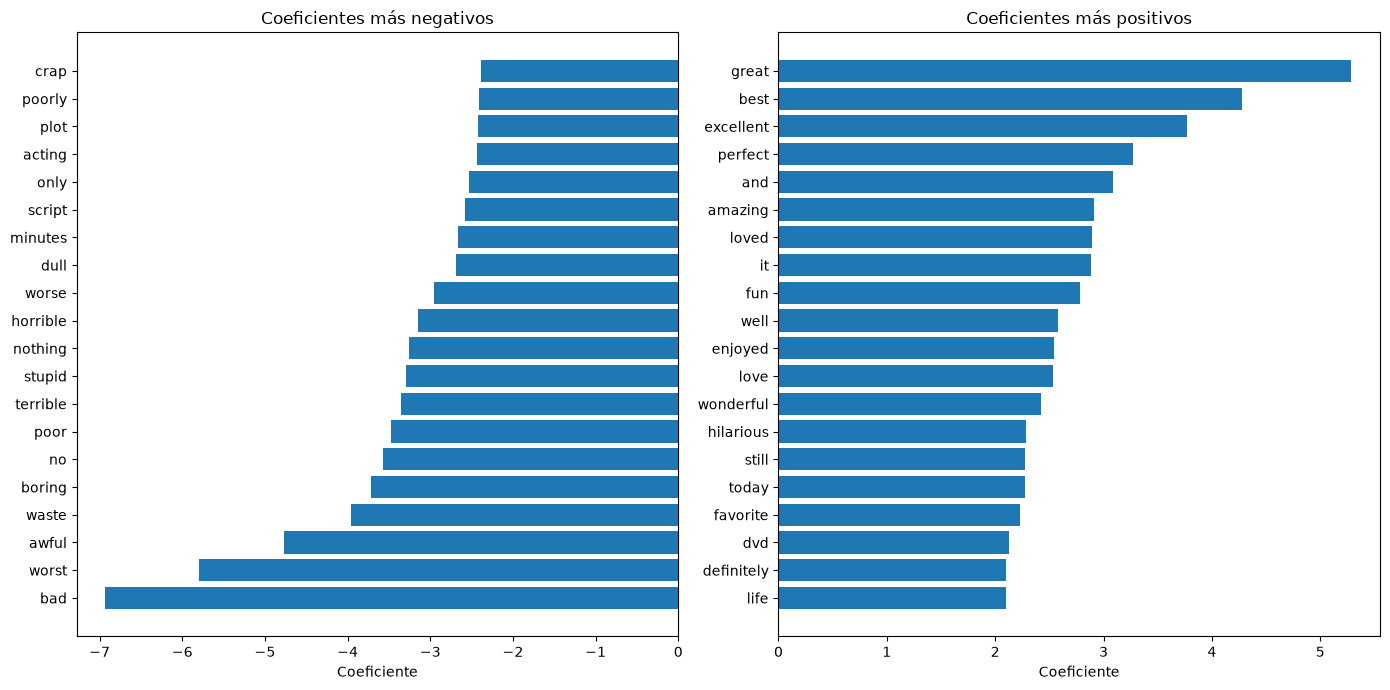

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].barh(
    most_negative["término"],
    most_negative["coeficiente"]
)
axes[0].set_title("Coeficientes más negativos")
axes[0].set_xlabel("Coeficiente")

axes[1].barh(
    most_positive.sort_values("coeficiente")["término"],
    most_positive.sort_values("coeficiente")["coeficiente"]
)
axes[1].set_title("Coeficientes más positivos")
axes[1].set_xlabel("Coeficiente")

plt.tight_layout()
plt.show()

## Ejercicio 7

1. ¿Las palabras más positivas y negativas son razonables?
2. ¿Encuentra nombres propios, términos raros o señales espurias?
3. ¿Un coeficiente alto demuestra causalidad?
4. ¿Cómo cambiarían los coeficientes si se modificara la limpieza?

In [41]:
# Solución Ejercicio 7
print("Top negativos:", most_negative["término"].tolist())
print("Top positivos:", most_positive["término"].tolist())

# Frecuencia documental de los términos más influyentes: los muy raros son sospechosos
vec = best_result["vectorizer"]
X_train_best = vec.transform(X_clean_train if best_result["text_version"] == "limpio" else X_raw_train)
doc_freq = dict(zip(vec.get_feature_names_out(), np.asarray((X_train_best > 0).sum(axis=0)).ravel()))
top_terms = pd.concat([most_negative.head(10), most_positive.head(10)])
top_terms["document_frequency"] = top_terms["término"].map(doc_freq)
display(top_terms.round(3))


Top negativos: ['bad', 'worst', 'awful', 'waste', 'boring', 'no', 'poor', 'terrible', 'stupid', 'nothing', 'horrible', 'worse', 'dull', 'minutes', 'script', 'only', 'acting', 'plot', 'poorly', 'crap']
Top positivos: ['great', 'best', 'excellent', 'perfect', 'and', 'amazing', 'loved', 'it', 'fun', 'well', 'enjoyed', 'love', 'wonderful', 'hilarious', 'still', 'today', 'favorite', 'dvd', 'definitely', 'life']


,término,coeficiente,document_frequency
378,bad,-6.930,1867
4955,worst,-5.798,649
371,awful,-4.766,470
4816,waste,-3.963,397
541,boring,-3.714,470
3020,no,-3.573,2641
3329,poor,-3.478,502
4420,terrible,-3.349,417
4260,stupid,-3.297,452
3048,nothing,-3.253,1084


### Respuesta Ejercicio 7

1. **¿Son razonables?** Sí, en su gran mayoría. Negativas: `bad`, `worst`, `awful`, `waste`, `boring`, `poor`, `terrible`, `stupid`, `horrible`, `dull`, `poorly`, `crap`. Positivas: `great`, `best`, `excellent`, `perfect`, `amazing`, `loved`, `enjoyed`, `wonderful`, `hilarious`, `favorite`. Es un léxico de sentimiento coherente.
2. **Señales espurias:** sí aparecen algunas.
   - **Stop words** con coeficientes altos: `and` (+3,09) y `it` (+2,89) en positivas; `only` en negativas. El mejor modelo usa texto original, así que estas palabras están en el vocabulario. Probablemente reflejan estilo (las reseñas positivas tienden a enumerar virtudes con "and"), no sentimiento.
   - **Palabras de contexto**, no evaluativas: `minutes` ("waste 90 minutes", "the last 20 minutes"), `script`, `plot` y `acting` en negativas (se critican más de lo que se elogian); `dvd`, `today`, `still` en positivas ("still holds up today", "buy the DVD").
   - No aparecen nombres propios en el top-20, gracias a `min_df=2` y `max_features=5000`, aunque podrían surgir en vocabularios más grandes.
3. **¿Un coeficiente alto demuestra causalidad?** No. Indica **asociación** condicional en este corpus y bajo este modelo. `minutes` no causa una mala reseña: co-ocurre con quejas. Además, los coeficientes dependen de la escala de las features, la regularización y la colinealidad entre palabras. Son útiles para interpretar y depurar, no para inferir causas.
4. **Si cambiara la limpieza:** con eliminación de stop words desaparecerían `and`, `it` y `only`, y su peso se redistribuiría hacia palabras correlacionadas. Sin expandir contracciones, `not` se partiría en `don`/`t`. Con stemming, `loved`/`love` se fusionarían y sumarían peso. Con bigramas aparecerían `not good` o `waste time` con coeficientes propios. En general, los coeficientes cambian tanto en magnitud como en ranking, porque el modelo reparte la evidencia entre las features disponibles.


# 8. Análisis de errores

Las métricas agregadas no explican por qué falla el modelo.

Revisaremos:

- Falsos positivos.
- Falsos negativos.
- Predicciones cercanas a 0.5.
- Negaciones.
- Reseñas ambiguas o con opiniones mixtas.

In [42]:
test_indices = best_result["test_index"]

error_df = df.loc[
    test_indices,
    [TEXT_COL, "review_clean", "sentiment_label", TARGET_COL]
].copy()

error_df["predicción"] = best_result["y_pred"]
error_df["probabilidad_positiva"] = best_result["y_prob"]

def classify_error(row):
    if row[TARGET_COL] == 0 and row["predicción"] == 1:
        return "false_positive"
    if row[TARGET_COL] == 1 and row["predicción"] == 0:
        return "false_negative"
    return "correct"

error_df["tipo"] = error_df.apply(classify_error, axis=1)
error_df["confianza"] = np.abs(error_df["probabilidad_positiva"] - 0.5)

display(error_df["tipo"].value_counts().to_frame("casos"))

,casos
tipo,
correct,1760
false_positive,136
false_negative,100


In [43]:
print("Ejemplos de falsos positivos:")
display(
    error_df.loc[
        error_df["tipo"] == "false_positive",
        [TEXT_COL, "sentiment_label", "probabilidad_positiva"]
    ].head(5)
)

print("Ejemplos de falsos negativos:")
display(
    error_df.loc[
        error_df["tipo"] == "false_negative",
        [TEXT_COL, "sentiment_label", "probabilidad_positiva"]
    ].head(5)
)

Ejemplos de falsos positivos:


,review,sentiment_label,probabilidad_positiva
552,"The riddle as a concept is an interesting idea, but i'm afraid is miscast, Vinnie if given the Hard man role is his element as in Lock Stock and Snatch. In this movie Vinnie pl...",negative,0.674798
1680,"Sunshine is a European import set in Hungary between 1880 and 1980, it's the epic story of Hungarian Jews, the Sonnenschein family. This name literally translates to Sunshine. ...",negative,0.555159
7213,"The Toxic Avenger, hideously deformed creature of super-human size and strength is back in this sequel that gets mostly everything wrong. Toxie goes to Japan to find his father...",negative,0.516193
6787,"Lone Star Productions sure churned them out in the 1930's, and ""Star Packer"" has the feel of one of the more rushed ones. John Wayne is U.S. Marshal John Travers, investigating...",negative,0.571230
5133,"This movie is full of pseudo deep thoughtfulness and it's cloying in its writerly-ness, that includes a canned ham voice-over and some unbelievable dialogue. Dialogue that is t...",negative,0.671327


Ejemplos de falsos negativos:


,review,sentiment_label,probabilidad_positiva
5283,"This is definitely one of the ultimate cult classics, and is a must see for all psychotronic fans. Why? It has everything a great 70s exploitation film should have. Over-the-to...",positive,0.453376
6750,"I just saw ""Behind Bedroom Doors,"" and this was the first softcore flick with a solid story behind it that I've seen in a while.<br /><br />We begin with two neighborly couples...",positive,0.319554
4713,"In France, it's considered polite from French critics to genuflect to the apparently cohesive chain of films Brian De Palma left behind him. However, a good proportion of his f...",positive,0.466523
1671,"Spending an hour seeing this brilliant Dan Finnerty and his ""Dan Band"" perform their special on Bravo is the most enjoyable hour I've ever spent watching TV. This young man (Da...",positive,0.435084
8945,"Boasting an all-star cast so impressive that it almost seems like the ""Mad Mad Mad Mad World"" of horror pictures, ""The Sentinel"" (1977) is nevertheless an effectively creepy fi...",positive,0.424330


In [44]:
print("Predicciones de menor confianza:")
display(
    error_df.sort_values("confianza")[
        [
            TEXT_COL,
            "sentiment_label",
            "predicción",
            "probabilidad_positiva",
            "tipo"
        ]
    ].head(10)
)

Predicciones de menor confianza:


,review,sentiment_label,predicción,probabilidad_positiva,tipo
7162,"This is a hard film to rate. While it truly deserves its 3 (or perhaps even a two), for an Al Adamson film, it's exceptional--and practically Adamson's very best. That's becaus...",negative,1,0.500277,false_positive
5532,This movie is basically about some girls in a Catholic school that end up getting into trouble because of putting red dye in one in one of their school mates shampoo and after ...,negative,0,0.499524,correct
3431,"Honestly, I have to admit that I go and see certain stupid films based on the hype they have generated or are currently generating. This dumb Salman Khan & Govinda feature is o...",negative,1,0.501010,false_positive
9037,"Good Times was a groundbreaking comedy about the first nuclear black family living in the Chicago projects. Whether or not, you live in the inner cities, ghettos, suburbs, or r...",positive,1,0.501152,correct
3123,"This is a cute little French silent comedy about a man who bets another that he can't stay in this castle for one hour due to its being haunted. And, once the guy enters the ho...",positive,1,0.501820,correct
6958,"It's a cooking competition show, Americanized. It's not going to be the Japanese version.<br /><br />The show is great. I could care less about cooking but this show is just en...",positive,1,0.502589,correct
7818,"Yes, it's another great magical Muppet's movie and I adore them all; the characters, the movies, the TV show episodes (it's the best comedy or musical TV show ever) and all the...",positive,1,0.502893,correct
8885,"I love John's work as a singer, but the movie was dull and 'no worth the time' to view. <br /><br />I thought he did an 'ok' job at acting his part. When he says, ""your having ...",negative,1,0.503257,false_positive
8455,"These are one of the movies that don't require any brain or thinking, it's a very funny time pass which you forgot in the next hour or so. I was really surprised with John Abra...",positive,1,0.503644,correct
8268,"Most successful comic book movies usually depend on having villains that are bigger than life, ready to jump off the screen and strangle you alive with a smile or a demented li...",positive,0,0.496236,false_negative


## Ejercicio 8

Revise al menos cinco errores.

1. ¿Hay sarcasmo?
2. ¿La reseña mezcla comentarios positivos y negativos?
3. ¿La negación está lejos del término evaluativo?
4. ¿El error parece causado por la limpieza?
5. ¿El error parece causado por ignorar el orden de las palabras?

In [45]:
# Solución Ejercicio 8
errors = error_df[error_df["tipo"] != "correct"].copy()
errors["contraste"] = errors[TEXT_COL].str.lower().str.contains(r"\b(but|however|although|though|yet)\b")
errors["negación"] = errors[TEXT_COL].str.lower().str.contains(r"\b(not|no|never)\b|n't")
errors["sarcasmo?"] = errors[TEXT_COL].str.lower().str.contains(r"\b(yeah right|oh great|so-called)\b|!{2,}|\?!")
errors["num_words"] = errors[TEXT_COL].str.split().str.len()

print("Total errores:", len(errors))
print(errors["tipo"].value_counts().to_dict())
print("Proporción de errores con conectores de contraste:", round(errors["contraste"].mean(), 3))
print("Proporción de aciertos con conectores de contraste:",
      round(error_df.loc[error_df["tipo"] == "correct", TEXT_COL].str.lower()
            .str.contains(r"\b(but|however|although|though|yet)\b").mean(), 3))

# Cinco errores más "seguros" (el modelo se equivocó con alta confianza)
worst = errors.sort_values("confianza", ascending=False).head(5)
for idx, row in worst.iterrows():
    print(f"\n--- {row['tipo']} | real={row['sentiment_label']} | P(pos)={row['probabilidad_positiva']:.3f} "
          f"| contraste={row['contraste']} | negación={row['negación']} ---")
    print(row[TEXT_COL][:700])


Total errores: 236
{'false_positive': 136, 'false_negative': 100}
Proporción de errores con conectores de contraste: 0.847
Proporción de aciertos con conectores de contraste: 0.781

--- false_positive | real=negative | P(pos)=0.900 | contraste=True | negación=True ---
'Major Payne' is a film about a major who makes life a living Hell for his small group of boys in the marines. This film does not really have a lot to offer, but it provides several hilarious moments that are well-worth a watch. Don't expect it to be a memorable film, however. Just expect to laugh your way through the film and at the expense of other people. The confrontation between Major Payne and the chubby boy were hilarious, and that's really all I remember about the film except for the boys wanting revenge on Major Payne. Again, it is not a great film, and it is probably best watched on a rainy day when you need some laughter.

--- false_positive | real=negative | P(pos)=0.884 | contraste=True | negación=True ---
In

### Respuesta Ejercicio 8

El mejor modelo comete **236 errores** sobre 1 996 reseñas de prueba: **136 falsos positivos** y **100 falsos negativos**. Tiende a ser algo optimista. Los cinco errores más confiados mostrados arriba:

| # | Tipo | P(pos) | Análisis |
|---|---|---:|---|
| 1 | FP (*Major Payne*) | 0,90 | **Mezcla** opiniones: "hilarious moments", "well-worth a watch", "best watched on a rainy day" junto con "not a great film", "does not have a lot to offer". La **negación** de `not great` se pierde al ignorar el orden, y `great`, `best` y `hilarious` suman positivo. |
| 2 | FP (*Romulus, My Father*) | 0,88 | Reseña larga que primero **resume la trama** con vocabulario neutro o positivo ("good-hearted", "happiness") antes del juicio negativo. El modelo pesa el contenido narrativo, no la opinión. |
| 3 | FP (*Ask the Dust*) | 0,85 | De nuevo, la descripción ("golden age", "great potential", "rich and famous and happy", "excellent novel") domina. El juicio negativo llega después y con palabras menos marcadas. |
| 4 | FN (*Modesty Blaise*) | 0,15 | Positiva, pero **argumenta contra críticas negativas**: "low budget with not good", "isn't part of it", "bad guy". Las palabras negativas están citadas o negadas ("not good" se refiere a otros). **Negación lejana** y orden ignorado. |
| 5 | FP (película de terror) | 0,85 | El texto es claramente elogioso ("great atmosphere", "would recommend everyone"), así que probablemente es **ruido en la etiqueta**: no todo error es del modelo. |

Respuestas:
1. **¿Sarcasmo?** No es el patrón dominante en estos casos. El sarcasmo existe en IMDB, pero aquí los errores vienen más de opiniones mixtas y negaciones. BoW/TF-IDF no puede detectarlo porque exige entender el contraste entre literalidad e intención.
2. **¿Mezcla de opiniones?** Sí, es el patrón más frecuente. El **84,7 %** de los errores contiene conectores de contraste (`but`, `however`, `although`, `though`, `yet`), frente al 78,1 % de los aciertos. Casos 1, 2 y 3.
3. **¿Negación lejos del término evaluativo?** Sí, en los casos 1 y 4 ("not a great film", "equate low budget with not good"). Con unigramas, `not` y `great` son features independientes.
4. **¿Causado por la limpieza?** No directamente: el mejor modelo usa **texto original**, sin limpieza. Con el modelo limpio, quitar `but`/`however` agravaría los casos mixtos.
5. **¿Causado por ignorar el orden?** Sí, es la causa principal. En BoW/TF-IDF la conclusión final ("Again, it is not a great film") pesa lo mismo que una frase descriptiva al inicio, y la negación no se asocia a su objeto. N-gramas (`not great`) o modelos secuenciales (transformers) mitigarían esto.


# 9. Conclusiones

En este notebook:

1. Exploramos el mismo dataset IMDB de la versión original.
2. Medimos balance, duplicados, longitudes, ruido y vocabulario.
3. Aplicamos una limpieza conservadora que preserva negaciones.
4. Construimos una matriz documento–término con Bag of Words.
5. Explicamos TF, DF, IDF y la normalización de TF-IDF.
6. Comparamos BoW y TF-IDF con texto original y limpio.
7. Interpretamos coeficientes de Logistic Regression.
8. Analizamos errores concretos.

## Idea central

BoW y TF-IDF convierten documentos en vectores dispersos y permiten utilizar álgebra lineal y machine learning. Son métodos simples, rápidos, interpretables y todavía útiles como baseline.

## Limitaciones compartidas

Ninguno comprende plenamente:

- Orden de palabras.
- Sintaxis.
- Sarcasmo.
- Contexto largo.
- Sinonimia.
- Polisemia.
- Significado profundo.

## Ejercicio final

Escriba una conclusión ejecutiva de máximo diez líneas:

1. ¿Cuál fue el mejor experimento?
2. ¿BoW o TF-IDF obtuvo mejores resultados?
3. ¿La limpieza ayudó?
4. ¿Qué términos fueron más importantes?
5. ¿Cuál fue el patrón de error más frecuente?
6. ¿Qué mejoraría en una siguiente iteración?

In [46]:
# Solución Ejercicio final
display(results_df[["experiment", "f1", "roc_auc", "accuracy"]].round(4))
print("Mejor experimento:", best_result["experiment"])
print("Errores:", error_df["tipo"].value_counts().to_dict())
print("Términos más negativos:", most_negative["término"].head(8).tolist())
print("Términos más positivos:", most_positive["término"].head(8).tolist())


,experiment,f1,roc_auc,accuracy
0,TF-IDF - texto original,0.8849,0.9506,0.8818
1,TF-IDF - texto limpio,0.8727,0.9460,0.8692
2,BoW - texto original,0.8597,0.9285,0.8572
3,BoW - texto limpio,0.8543,0.9235,0.8522


Mejor experimento: TF-IDF - texto original
Errores: {'correct': 1760, 'false_positive': 136, 'false_negative': 100}
Términos más negativos: ['bad', 'worst', 'awful', 'waste', 'boring', 'no', 'poor', 'terrible']
Términos más positivos: ['great', 'best', 'excellent', 'perfect', 'and', 'amazing', 'loved', 'it']


### Respuesta Ejercicio final

**Conclusión ejecutiva**

1. El **mejor experimento fue TF-IDF + Logistic Regression sobre el texto original**: F1 = 0,885, ROC-AUC = 0,951, accuracy = 0,882.
2. **TF-IDF superó a BoW** en las dos versiones del texto (+2,5 puntos de F1, +2,2 de ROC-AUC), porque penaliza las palabras ubicuas y normaliza por longitud.
3. **La limpieza no ayudó:** redujo F1 entre 0,5 y 1,2 puntos. Quitar stop words y números elimina señales útiles (`but`, `only`, "1/10"); con un modelo regularizado basta una limpieza mínima (HTML).
4. **Términos más importantes:** negativos `bad`, `worst`, `awful`, `waste`, `boring`, `poor`, `terrible`; positivos `great`, `best`, `excellent`, `perfect`, `amazing`, `loved`. También hay señales espurias como `and`, `it` y `minutes`.
5. **Patrón de error dominante:** reseñas con **opiniones mixtas** y conectores de contraste (85 % de los errores), con negaciones lejanas que el modelo no puede asociar por ignorar el orden. Hay más falsos positivos (136) que falsos negativos (100), y algo de ruido en las etiquetas.
6. **Siguiente iteración:** añadir **bigramas** (`ngram_range=(1,2)`) para capturar `not good`, ajustar `C` y `max_features` con validación cruzada, probar limpieza mínima (solo HTML) y, como siguiente salto, embeddings o un transformer preentrenado (p. ej. DistilBERT) que modele contexto y orden.


# Anexo opcional: predicción de nuevas reseñas

La siguiente función reutiliza el mejor vectorizador y el mejor modelo. Si el mejor experimento fue entrenado con texto limpio, aplica automáticamente la misma función de limpieza.

En producción, el preprocesamiento, el vectorizador y el modelo deberían almacenarse juntos en un `Pipeline`.

In [47]:
def predict_sentiment(text):
    if best_result["text_version"] == "limpio":
        model_text = clean_text(text)
    else:
        model_text = str(text)

    vector = best_result["vectorizer"].transform([model_text])
    probability_positive = best_result["model"].predict_proba(vector)[0, 1]
    prediction = int(probability_positive >= 0.5)

    return {
        "texto": text,
        "predicción": "positive" if prediction == 1 else "negative",
        "probabilidad_positive": round(float(probability_positive), 4)
    }


predict_sentiment("This movie was surprisingly good and never boring.")

{'texto': 'This movie was surprisingly good and never boring.',
 'predicción': 'negative',
 'probabilidad_positive': 0.2287}

# Referencias

- Manning, C. D., Raghavan, P., & Schütze, H. (2008). *Introduction to Information Retrieval*. Cambridge University Press.
- Jurafsky, D., & Martin, J. H. *Speech and Language Processing*.
- Scikit-learn documentation: `CountVectorizer`, `TfidfVectorizer` y `LogisticRegression`.